<a href="https://colab.research.google.com/github/Fugant1/bioinformatics-task/blob/main/PCA_vs_LDA_RNASeq_TCGA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PCA × LDA em dados de expressão gênica (RNA-Seq do TCGA)

**SCC02713 – Introdução à Bioinformática**
Notebook prático das **Aula 10 (PCA)** e **Aula 11 (LDA)**

---

### Objetivos

Ao final deste notebook você deverá ser capaz de:

1. Reproduzir **passo a passo** o PCA visto em aula (centralizar → ajustar a reta → vetor unitário/loadings → autovalores → % de variação → SVD).
2. Entender o **critério de Fisher** do LDA: maximizar a distância entre as médias e, *ao mesmo tempo*, minimizar a variância dentro de cada classe.
3. Aplicar **PCA** e **LDA** a um conjunto de dados real e grande de RNA-Seq (**801 tumores × 20.531 genes**, 5 tipos de câncer).
4. Comparar as duas técnicas: **não supervisionada × supervisionada**, número máximo de componentes, *loading scores* e o risco de **sobreajuste** do LDA quando há muito mais genes do que amostras.

### Roteiro

| Parte | Conteúdo |
|---|---|
| 0 | Preparação do ambiente |
| 1 | PCA "na mão" com o exemplo dos 6 ratos da aula |
| 2 | LDA "na mão": por que não basta maximizar *d*? |
| 3 | O conjunto de dados real (TCGA Pan-Cancer) |
| 4 | PCA nos dados reais |
| 5 | LDA nos dados reais (e a armadilha do sobreajuste com rótulos aleatórios) |
| 6 | PCA × LDA lado a lado |
| 7 | Resumo e exercícios |

> **Como usar:** execute as células **em ordem**, de cima para baixo (`Ambiente de execução → Executar tudo`, ou `Shift+Enter` célula a célula). Leia os comentários: eles são parte da aula.

---
## Parte 0 — Preparação do ambiente

Todas as bibliotecas abaixo já vêm instaladas no Google Colab.

- **numpy / pandas**: manipulação de matrizes e tabelas.
- **matplotlib / seaborn**: gráficos.
- **scikit-learn**: implementações prontas de PCA, LDA e ferramentas de avaliação.

In [11]:
# ---------------------------------------------------------------
# Importação das bibliotecas
# ---------------------------------------------------------------
import os, glob, zipfile, tarfile, time, urllib.request   # utilitários de arquivo e download

import numpy as np                 # álgebra linear (vetores, matrizes, SVD)
import pandas as pd                # tabelas (DataFrames)
import matplotlib.pyplot as plt    # gráficos
import seaborn as sns              # gráficos estatísticos mais bonitos

from sklearn.decomposition import PCA                                  # Análise de Componentes Principais
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis   # Análise Discriminante Linear
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Semente aleatória: garante que todos obtenham os mesmos resultados
SEED = 42
np.random.seed(SEED)

# Estilo padrão dos gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print("Bibliotecas carregadas!")

Bibliotecas carregadas!


---
## Parte 1 — PCA "na mão" com o exemplo da aula

Vamos começar com a tabela da **Aula 10**: expressão de **2 genes** medida em **6 ratos**.

Atenção a um detalhe de **orientação da tabela**:

- Nos slides, **genes estão nas linhas** e **ratos (amostras) nas colunas**.
- No scikit-learn (e na maioria das bibliotecas de aprendizado de máquina) a convenção é a oposta: **cada linha é uma amostra** e **cada coluna é uma variável (gene)**.

Por isso vamos **transpor** a tabela (`.T`).

In [12]:
# ---------------------------------------------------------------
# Tabela do slide 2 da Aula 10 (genes nas linhas, ratos nas colunas)
# ---------------------------------------------------------------
tabela_slide = pd.DataFrame(
    {"Mouse 1": [10, 6], "Mouse 2": [11, 4], "Mouse 3": [8, 5],
     "Mouse 4": [3, 3],  "Mouse 5": [1, 2.8], "Mouse 6": [2, 1]},
    index=["Gene 1", "Gene 2"])
print("Como no slide (genes × amostras):")
display(tabela_slide)

# Transpomos: agora cada LINHA é um rato e cada COLUNA é um gene
X_ratos = tabela_slide.T
print("Formato usado pelo scikit-learn (amostras × genes):")
display(X_ratos)

Como no slide (genes × amostras):


,Mouse 1,Mouse 2,Mouse 3,Mouse 4,Mouse 5,Mouse 6
Gene 1,10,11,8,3,1.0,2
Gene 2,6,4,5,3,2.8,1


Formato usado pelo scikit-learn (amostras × genes):


,Gene 1,Gene 2
Mouse 1,10.0,6.0
Mouse 2,11.0,4.0
Mouse 3,8.0,5.0
Mouse 4,3.0,3.0
Mouse 5,1.0,2.8
Mouse 6,2.0,1.0


### Passo 1 — Calcular a média de cada gene e centralizar os dados

Nos slides: *"Calcula a média para o Gene 1... e a média para o Gene 2"* e depois *"Centra os dados na origem"*.

Centralizar é subtrair de cada valor a média do seu gene. O resultado é que o **centro dos dados vai para a origem (0, 0)**, mas as **posições relativas entre os pontos não mudam**.

Média de cada gene:
 Gene 1    5.833333
Gene 2    3.633333
dtype: float64 

Dados centralizados (a média de cada coluna agora é 0):


,Gene 1,Gene 2
Mouse 1,4.17,2.37
Mouse 2,5.17,0.37
Mouse 3,2.17,1.37
Mouse 4,-2.83,-0.63
Mouse 5,-4.83,-0.83
Mouse 6,-3.83,-2.63


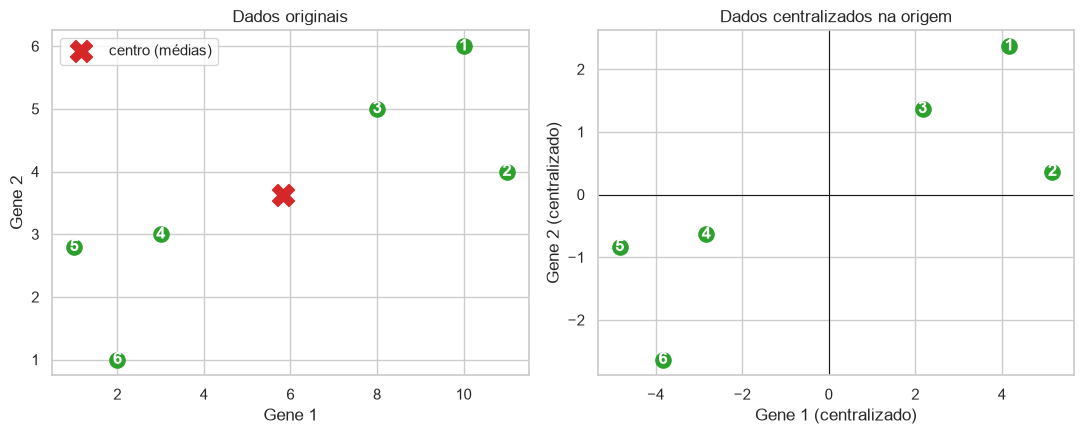

In [13]:
# Média de cada gene (média de cada coluna)
medias = X_ratos.mean(axis=0)
print("Média de cada gene:\n", medias, "\n")

# Centralização: subtrai a média do gene em cada amostra
Xc = X_ratos - medias
print("Dados centralizados (a média de cada coluna agora é 0):")
display(Xc.round(2))

# --- Visualização: antes e depois de centralizar ---
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

ax[0].scatter(X_ratos["Gene 1"], X_ratos["Gene 2"], s=120, c="tab:green")
ax[0].scatter(*medias, marker="X", s=250, c="tab:red", label="centro (médias)")
for nome, (g1, g2) in X_ratos.iterrows():
    ax[0].annotate(nome.split()[-1], (g1, g2), ha="center", va="center", color="white", fontweight="bold")
ax[0].set(title="Dados originais", xlabel="Gene 1", ylabel="Gene 2")
ax[0].legend()

ax[1].scatter(Xc["Gene 1"], Xc["Gene 2"], s=120, c="tab:green")
ax[1].axhline(0, c="k", lw=0.8); ax[1].axvline(0, c="k", lw=0.8)
for nome, (g1, g2) in Xc.iterrows():
    ax[1].annotate(nome.split()[-1], (g1, g2), ha="center", va="center", color="white", fontweight="bold")
ax[1].set(title="Dados centralizados na origem", xlabel="Gene 1 (centralizado)", ylabel="Gene 2 (centralizado)")
plt.tight_layout(); plt.show()

### Passo 2 — Encontrar a reta que melhor se ajusta (girando a reta!)

Nos slides: *"Começamos com uma reta aleatória que passa pela origem"* e *"Rotacionamos a reta até que ela se ajuste bem aos dados"*.

Para cada reta (definida por um ângulo θ), projetamos os pontos perpendicularmente sobre ela e medimos:

- **c** = distância do ponto projetado até a origem;
- **b** = distância do ponto até a reta.

Pelo **Teorema de Pitágoras**, `a² = b² + c²`, e **a** (distância do ponto à origem) é fixa. Logo, **maximizar a soma dos c²** é exatamente o mesmo que **minimizar a soma dos b²**. O PCA escolhe a reta com a **maior SS(distâncias)** = soma dos c².

Vamos testar 180 ângulos e ver qual vence.

Ângulo com MAIOR soma de c²:  19°
Ângulo com MENOR soma de b²:  19°   <- é o mesmo ângulo!
Soma c² + b² é constante? True  (é a soma dos a²)


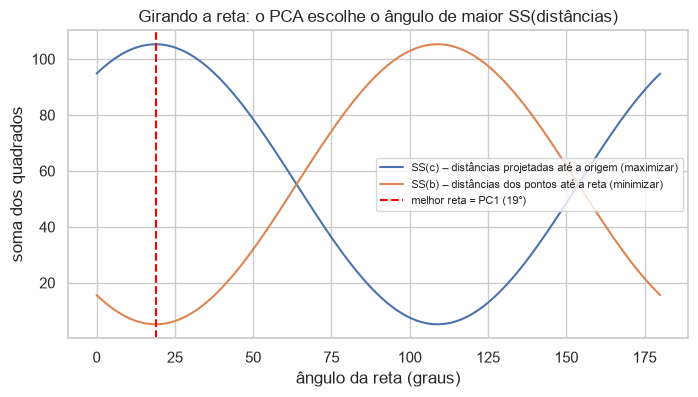

In [14]:
X_np = Xc.to_numpy()   # dados centralizados como matriz numpy (6 × 2)

angulos = np.linspace(0, 180, 181)   # ângulos de 0° a 180° (em graus)
SS_c, SS_b = [], []                  # soma dos c² e soma dos b² para cada ângulo

for theta in angulos:
    # vetor unitário (comprimento 1) que aponta na direção da reta
    u = np.array([np.cos(np.radians(theta)), np.sin(np.radians(theta))])
    c = X_np @ u                                 # c = projeção de cada ponto na reta (produto escalar)
    a2 = (X_np ** 2).sum(axis=1)                 # a² = distância² de cada ponto à origem
    b2 = a2 - c ** 2                             # Pitágoras: b² = a² - c²
    SS_c.append((c ** 2).sum())
    SS_b.append(b2.sum())

SS_c, SS_b = np.array(SS_c), np.array(SS_b)
melhor = angulos[SS_c.argmax()]
print(f"Ângulo com MAIOR soma de c²:  {melhor:.0f}°")
print(f"Ângulo com MENOR soma de b²:  {angulos[SS_b.argmin()]:.0f}°   <- é o mesmo ângulo!")
print(f"Soma c² + b² é constante? {np.allclose(SS_c + SS_b, SS_c[0] + SS_b[0])}  (é a soma dos a²)")

plt.figure(figsize=(8, 4))
plt.plot(angulos, SS_c, label="SS(c) – distâncias projetadas até a origem (maximizar)")
plt.plot(angulos, SS_b, label="SS(b) – distâncias dos pontos até a reta (minimizar)")
plt.axvline(melhor, c="red", ls="--", label=f"melhor reta = PC1 ({melhor:.0f}°)")
plt.xlabel("ângulo da reta (graus)"); plt.ylabel("soma dos quadrados")
plt.title("Girando a reta: o PCA escolhe o ângulo de maior SS(distâncias)")
plt.legend(fontsize=8); plt.show()

### Passo 2b — Visualizando o laço: gire a reta você mesmo!

A célula abaixo desenha **exatamente** o que o laço `for theta in angulos` calcula, para um ângulo θ de cada vez. Arraste o controle deslizante:

- **reta vermelha tracejada** e a setinha **u**: a direção da reta, `u = [cos θ, sin θ]` (comprimento 1);
- **segmento preto a**: distância do Rato 1 até a origem — **não muda** quando a reta gira (`a2`);
- **segmento vermelho c**: onde o Rato 1 "cai" na reta, medido a partir da origem (`c = X_np @ u`);
- **segmento azul b**: distância perpendicular do Rato 1 até a reta (`b2 = a2 - c**2`), com o ângulo reto marcado;
- pontinhos vermelhos: as projeções dos outros 5 ratos.

Observe o quadro de valores: **c² + b² = a²** fica sempre igual, e **SS(c) + SS(b)** também. Por isso o ângulo que **maximiza SS(c)** é o mesmo que **minimiza SS(b)** — e essa reta é a **PC1**.

In [15]:
import ipywidgets as widgets
from ipywidgets import interact

def desenha_projecao(theta=60):
    # ----- 1) A reta para este ângulo: vetor unitário u -----
    rad = np.radians(theta)
    u = np.array([np.cos(rad), np.sin(rad)])

    # ----- 2) As mesmas contas do laço, para este θ -----
    c  = X_np @ u                      # projeção de cada rato na reta
    a2 = (X_np ** 2).sum(axis=1)       # distância² de cada rato até a origem
    b2 = a2 - c ** 2                   # distância² de cada rato até a reta (Pitágoras)

    fig, ax = plt.subplots(figsize=(8, 6.5))
    ax.axhline(0, c="gray", lw=0.8); ax.axvline(0, c="gray", lw=0.8)

    # A reta (desenhada bem comprida nos dois sentidos) e o vetor unitário u
    ax.plot([-8 * u[0], 8 * u[0]], [-8 * u[1], 8 * u[1]], "--", c="red", lw=1.5)
    ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="red", lw=2))
    n_u = np.array([-u[1], u[0]])                     # direção perpendicular a u (só para posicionar o rótulo)
    ax.text(*(1.1 * u + 0.3 * n_u), "u", color="red", fontsize=12, ha="center", va="center")

    # Arco do ângulo θ, medido a partir do eixo do Gene 1
    arco = np.radians(np.linspace(0, theta, 50))
    ax.plot(0.9 * np.cos(arco), 0.9 * np.sin(arco), c="black", lw=1)
    meio = np.radians(theta / 2)
    ax.text(0.55 * np.cos(meio), 0.55 * np.sin(meio), "θ", fontsize=11, ha="center", va="center")

    # Outros ratos: ponto, linha pontilhada até a reta e a projeção
    for i in range(1, len(X_np)):
        p, proj = X_np[i], c[i] * u
        ax.plot([p[0], proj[0]], [p[1], proj[1]], ":", c="gray", lw=1)
        ax.scatter(*proj, c="red", s=20, alpha=0.6, zorder=3)
        ax.scatter(*p, c="yellowgreen", s=180, zorder=4)
        ax.text(*p, str(i + 1), ha="center", va="center", fontsize=9, zorder=5)

    # Rato 1 em destaque: o triângulo a, b, c
    p, proj = X_np[0], c[0] * u
    ax.plot([0, p[0]], [0, p[1]], c="black", lw=2)                   # a
    ax.plot([0, proj[0]], [0, proj[1]], c="red", lw=5, alpha=0.8)     # c
    ax.plot([p[0], proj[0]], [p[1], proj[1]], "--", c="tab:blue", lw=2)  # b
    ax.scatter(*p, c="green", s=220, zorder=4)
    ax.text(*p, "1", ha="center", va="center", color="white", fontweight="bold", zorder=5)
    n_a = np.array([-p[1], p[0]]) / np.linalg.norm(p)            # perpendicular ao segmento a
    if n_a @ (proj - p) > 0: n_a = -n_a                           # rótulo do lado oposto à reta
    ax.text(*(0.6 * p + 0.35 * n_a), "a", fontsize=14, fontweight="bold", ha="center", va="center")
    ax.text(*(proj / 2 + np.array([0.25, -0.45])), "c", fontsize=14, fontweight="bold", color="red")
    ax.text(*((p + proj) / 2 + 0.3 * np.sign(c[0] or 1) * u), "b", fontsize=14, fontweight="bold", color="tab:blue")

    # Marca do ângulo reto entre b e a reta (no ponto projetado)
    if np.sqrt(b2[0]) > 0.3:
        d = (p - proj) / np.linalg.norm(p - proj)          # direção de b
        s = 0.3; sgn = np.sign(c[0]) or 1
        q1 = proj - sgn * s * u; q2 = q1 + s * d; q3 = proj + s * d
        ax.plot([q1[0], q2[0], q3[0]], [q1[1], q2[1], q3[1]], c="black", lw=1)

    # Quadro com os valores (os mesmos números que o laço guarda)
    texto = (f"θ = {theta}°\n"
             f"u = [{u[0]:.3f}, {u[1]:.3f}]\n\n"
             f"Rato 1:\n"
             f"  a² = {a2[0]:.2f}  (fixo)\n"
             f"  c² = {c[0]**2:.2f}\n"
             f"  b² = {b2[0]:.2f}\n"
             f"  c² + b² = {c[0]**2 + b2[0]:.2f}\n\n"
             f"Todos os 6 ratos:\n"
             f"  SS(c) = {(c**2).sum():.2f}\n"
             f"  SS(b) = {b2.sum():.2f}\n"
             f"  soma  = {(c**2).sum() + b2.sum():.2f}  (fixo)")
    if abs(theta - melhor) <= 1:
        texto += "\n\n  <- MÁXIMO de SS(c): PC1!"
    ax.text(1.03, 0.98, texto, transform=ax.transAxes, va="top", family="monospace", fontsize=10,
            bbox=dict(boxstyle="round", fc="whitesmoke", ec="lightgray"))

    ax.set(xlim=(-6.5, 6.5), ylim=(-5, 5), aspect="equal",
           xlabel="Gene 1 (centralizado)", ylabel="Gene 2 (centralizado)",
           title=f"Reta girada em θ = {theta}°")
    plt.show()

# Controle deslizante: de 0° a 180°, de 1 em 1 grau
interact(desenha_projecao,
         theta=widgets.IntSlider(value=60, min=0, max=180, step=1, description="θ (graus)",
                                 continuous_update=True, layout=widgets.Layout(width="500px")));

interactive(children=(IntSlider(value=60, description='θ (graus)', layout=Layout(width='500px'), max=180), Out…

### Passo 3 — Vetor unitário, *loading scores*, autovalores e % de variação

Na aula a reta foi descrita pela inclinação (por exemplo, "4 unidades em x para 1 em y"), e depois **redimensionada para ter comprimento 1**. Esse vetor unitário é o **autovetor (vetor singular) da PC1**, e seus componentes são os **loading scores**.

Em seguida:

- **Autovalor** da PC = SS(distâncias) dos pontos projetados naquela PC;
- **Variação** da PC = autovalor / (n − 1);
- **% de variação explicada** = variação da PC / soma das variações de todas as PCs.

> 💡 Os números dos slides (0,97 e 0,242) eram **ilustrativos**, vindos do vídeo-base da aula. Aqui calculamos os valores **exatos** para essa tabela de 6 ratos.

In [16]:
n = X_np.shape[0]   # número de amostras (6 ratos)

# Vetor unitário da melhor reta encontrada pela busca de ângulos
pc1 = np.array([np.cos(np.radians(melhor)), np.sin(np.radians(melhor))])
# PC2: em 2D, é simplesmente a reta perpendicular a PC1 (gira 90°)
pc2 = np.array([-pc1[1], pc1[0]])

print("Loading scores (vetor unitário) da PC1:", pc1.round(3))
print("   -> inclinação da reta:", round(pc1[1] / pc1[0], 3),
      f"(ou seja, a cada {pc1[0]/pc1[1]:.1f} unidades no Gene 1 subimos 1 no Gene 2)")
print("   -> comprimento do vetor (Pitágoras):", round(np.sqrt((pc1 ** 2).sum()), 3))
print("Loading scores da PC2:", pc2.round(3), "\n")

# Autovalores = SS(distâncias) das projeções em cada PC
autoval_pc1 = ((X_np @ pc1) ** 2).sum()
autoval_pc2 = ((X_np @ pc2) ** 2).sum()
var_pc1, var_pc2 = autoval_pc1 / (n - 1), autoval_pc2 / (n - 1)
total = var_pc1 + var_pc2

print(f"Autovalor PC1 = SS = {autoval_pc1:.2f}  ->  variação = {var_pc1:.2f}")
print(f"Autovalor PC2 = SS = {autoval_pc2:.2f}  ->  variação = {var_pc2:.2f}")
print(f"PC1 explica {100*var_pc1/total:.1f}% da variação; PC2 explica {100*var_pc2/total:.1f}%")
print(f"Valor singular da PC1 = raiz(autovalor) = {np.sqrt(autoval_pc1):.3f}")

Loading scores (vetor unitário) da PC1: [0.946 0.326]
   -> inclinação da reta: 0.344 (ou seja, a cada 2.9 unidades no Gene 1 subimos 1 no Gene 2)
   -> comprimento do vetor (Pitágoras): 1.0
Loading scores da PC2: [-0.326  0.946] 

Autovalor PC1 = SS = 105.30  ->  variação = 21.06
Autovalor PC2 = SS = 5.17  ->  variação = 1.03
PC1 explica 95.3% da variação; PC2 explica 4.7%
Valor singular da PC1 = raiz(autovalor) = 10.261


#### Por que `pc2 = [-pc1[1], pc1[0]]` é a reta perpendicular?

Trocar os dois números de lugar e pôr um sinal de menos no primeiro **gira o vetor 90°**. A figura mostra que os dois triângulos tracejados são o **mesmo triângulo, girado**: o cateto "deitado" da PC1 vira o cateto "em pé" da PC2, e vice-versa (agora apontando para a esquerda, daí o sinal de menos).

Conferências: o **produto escalar** entre os dois é zero (= ângulo de 90°) e os dois têm **comprimento 1**.

Ângulo da PC1: 19.0°  |  Ângulo da PC2: 109.0°  |  diferença: 90.0°
Produto escalar pc1 · pc2 = 0.000000   (zero => perpendiculares)
Comprimentos: |pc1| = 1.000, |pc2| = 1.000


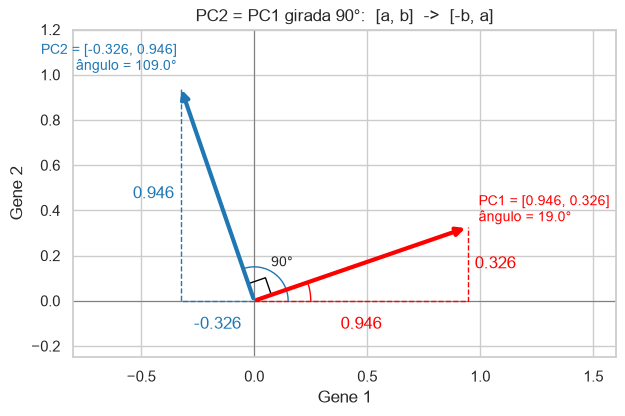

In [17]:
ang_pc1 = np.degrees(np.arctan2(pc1[1], pc1[0]))   # ângulo da PC1 em relação ao eixo do Gene 1
ang_pc2 = np.degrees(np.arctan2(pc2[1], pc2[0]))   # ângulo da PC2
print(f"Ângulo da PC1: {ang_pc1:.1f}°  |  Ângulo da PC2: {ang_pc2:.1f}°  |  diferença: {ang_pc2 - ang_pc1:.1f}°")
print(f"Produto escalar pc1 · pc2 = {pc1 @ pc2:.6f}   (zero => perpendiculares)")
print(f"Comprimentos: |pc1| = {np.linalg.norm(pc1):.3f}, |pc2| = {np.linalg.norm(pc2):.3f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.axhline(0, c="gray", lw=0.8); ax.axvline(0, c="gray", lw=0.8)

for v, cor, nome, ang in [(pc1, "red", "PC1", ang_pc1), (pc2, "tab:blue", "PC2", ang_pc2)]:
    ax.plot([0, v[0], v[0]], [0, 0, v[1]], "--", c=cor, lw=1)          # catetos do triângulo
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=cor, lw=3))
    ax.text(v[0] * 1.05, v[1] * 1.08, f"{nome} = [{v[0]:.3f}, {v[1]:.3f}]\nângulo = {ang:.1f}°",
            color=cor, fontsize=10, ha="left" if v[0] > 0 else "right")
    ax.text(v[0] / 2, -0.07, f"{v[0]:.3f}", color=cor, ha="center", va="top")       # cateto deitado
    ax.text(v[0] + (0.03 if v[0] > 0 else -0.03), v[1] / 2, f"{v[1]:.3f}", color=cor,
            ha="left" if v[0] > 0 else "right", va="center")                         # cateto em pé

# Arcos dos ângulos a partir do eixo do Gene 1
for ang, cor, r in [(ang_pc1, "red", 0.25), (ang_pc2, "tab:blue", 0.15)]:
    t = np.radians(np.linspace(0, ang, 60))
    ax.plot(r * np.cos(t), r * np.sin(t), c=cor, lw=1)

# Marca do ângulo reto entre PC1 e PC2
s = 0.08
q = [s * pc1, s * pc1 + s * pc2, s * pc2]
ax.plot([q[0][0], q[1][0], q[2][0]], [q[0][1], q[1][1], q[2][1]], c="black", lw=1)
ax.text(*(0.12 * (pc1 + pc2)), "90°", fontsize=10)

ax.set(xlim=(-0.8, 1.6), ylim=(-0.25, 1.2), aspect="equal", xlabel="Gene 1", ylabel="Gene 2",
       title="PC2 = PC1 girada 90°:  [a, b]  ->  [-b, a]")
plt.show()

### Passo 4 — O mesmo resultado, de uma vez só, com o SVD

No fim da Aula 10 vimos que o **SVD** encontra todos os PCs de uma vez:

$$X = U\,\Sigma\,V^T$$

- colunas de **V** → vetores singulares (autovetores) = *loading scores*;
- diagonal de **Σ** → valores singulares; ao quadrado = autovalores (SS);
- **U·Σ** → coordenadas das amostras nos novos eixos (as projeções).

Vamos conferir que o SVD do numpy e o `PCA` do scikit-learn dão **o mesmo** que a nossa busca "girando a reta".

> ⚠️ **Sinal dos vetores:** um autovetor e o seu oposto (multiplicado por −1) representam a **mesma reta**. Por isso bibliotecas diferentes podem devolver sinais trocados; isso não muda nada na interpretação.

In [18]:
# ---- SVD manual com numpy ----
U, S, Vt = np.linalg.svd(X_np, full_matrices=False)
print("Valores singulares (Σ):", S.round(3))
print("Autovalores = Σ²     :", (S ** 2).round(2), " (compare com as SS calculadas acima)")
print("Loadings (colunas de V):\n", Vt.T.round(3))
print("Coordenadas U·Σ (projeções das amostras):\n", (U * S).round(2), "\n")

# ---- PCA do scikit-learn (ele centraliza sozinho!) ----
pca_ratos = PCA(n_components=2).fit(X_ratos)
print("scikit-learn — loadings (cada LINHA é uma PC):\n", pca_ratos.components_.round(3))
print("scikit-learn — variação de cada PC (autovalor/(n-1)):", pca_ratos.explained_variance_.round(2))
print("scikit-learn — % variação explicada:", (100 * pca_ratos.explained_variance_ratio_).round(1))

Valores singulares (Σ): [10.262  2.273]
Autovalores = Σ²     : [105.3    5.17]  (compare com as SS calculadas acima)
Loadings (colunas de V):
 [[-0.946 -0.323]
 [-0.323  0.946]]
Coordenadas U·Σ (projeções das amostras):
 [[-4.71  0.89]
 [-5.01 -1.32]
 [-2.49  0.59]
 [ 2.89  0.32]
 [ 4.84  0.77]
 [ 4.48 -1.25]] 

scikit-learn — loadings (cada LINHA é uma PC):
 [[ 0.946  0.323]
 [-0.323  0.946]]
scikit-learn — variação de cada PC (autovalor/(n-1)): [21.06  1.03]
scikit-learn — % variação explicada: [95.3  4.7]


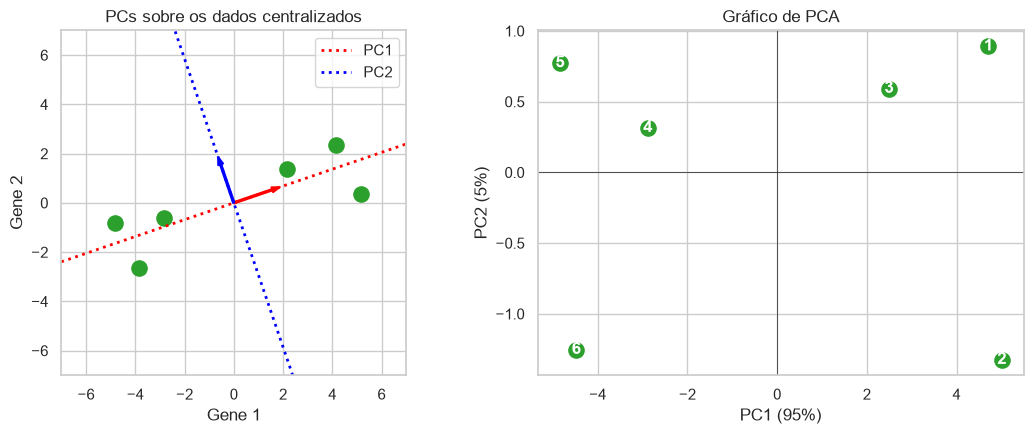

In [19]:
# Visualização final do exemplo dos ratos: PC1 e PC2 sobre os dados, e o gráfico de PCA
coords = pca_ratos.transform(X_ratos)    # projeções das amostras em PC1 e PC2
ev = 100 * pca_ratos.explained_variance_ratio_

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(X_np[:, 0], X_np[:, 1], s=120, c="tab:green")
for v, cor, nome in [(pca_ratos.components_[0], "red", "PC1"), (pca_ratos.components_[1], "blue", "PC2")]:
    ax[0].plot(*np.c_[-8 * v, 8 * v], ls=":", c=cor, lw=2, label=nome)       # a reta
    ax[0].arrow(0, 0, *(2 * v), color=cor, width=0.08, length_includes_head=True)  # o vetor unitário (×2 p/ ver)
ax[0].set(xlim=(-7, 7), ylim=(-7, 7), aspect="equal", title="PCs sobre os dados centralizados",
          xlabel="Gene 1", ylabel="Gene 2")
ax[0].legend()

ax[1].scatter(coords[:, 0], coords[:, 1], s=120, c="tab:green")
for i, nome in enumerate(X_ratos.index):
    ax[1].annotate(nome.split()[-1], coords[i], ha="center", va="center", color="white", fontweight="bold")
ax[1].axhline(0, c="k", lw=.5); ax[1].axvline(0, c="k", lw=.5)
ax[1].set(title="Gráfico de PCA", xlabel=f"PC1 ({ev[0]:.0f}%)", ylabel=f"PC2 ({ev[1]:.0f}%)")
plt.tight_layout(); plt.show()

**Para pensar:** os ratos 1, 2 e 3 formam um grupo e os ratos 4, 5 e 6 formam outro, como nos slides. Repare que o PCA **não sabia** que existiam dois grupos — ele só procurou a direção de maior variação. É por isso que o PCA é uma técnica **não supervisionada**.

---
## Parte 2 — LDA "na mão": por que não basta maximizar *d*?

Na **Aula 11** vimos que o LDA cria um novo eixo usando **dois critérios simultâneos**:

1. **maximizar** a distância entre as médias das classes (*d*);
2. **minimizar** a variância *s²* dentro de cada classe.

Ou seja, ele maximiza a **razão de Fisher**:

$$J = \frac{d^2}{s_1^2 + s_2^2} = \frac{\text{idealmente grande}}{\text{idealmente pequeno}}$$

Vamos recriar o exemplo do slide *"Por que não apenas maximizamos d?"*: duas classes com nuvens alongadas e paralelas. Compararemos **três** direções de projeção:

| Direção | O que ela otimiza |
|---|---|
| **Só d** | apenas a distância entre as médias (direção que liga as duas médias) |
| **PCA (PC1)** | a variância total, **ignorando as classes** |
| **LDA (LD1)** | a razão de Fisher (médias longe **e** classes compactas) |

In [20]:
# ---------------------------------------------------------------
# Dados simulados: 2 classes, 2 genes, nuvens alongadas e paralelas
# (imitando o slide "Por que não apenas maximizamos d?")
# ---------------------------------------------------------------
rng = np.random.default_rng(SEED)
n_por_classe = 60

# Covariância "esticada" ao longo da diagonal: as nuvens são alongadas
cov = np.array([[3.0, 2.6],
                [2.6, 3.0]])
classe_A = rng.multivariate_normal(mean=[0, 0],   cov=cov, size=n_por_classe)  # droga funciona (verde)
classe_B = rng.multivariate_normal(mean=[2, 3.5], cov=cov, size=n_por_classe)  # droga não funciona (vermelho)

X2 = np.vstack([classe_A, classe_B])                     # matriz 120 × 2
y2 = np.array([0] * n_por_classe + [1] * n_por_classe)   # rótulos: 0 = A, 1 = B
print("Formato dos dados simulados:", X2.shape)

Formato dos dados simulados: (120, 2)


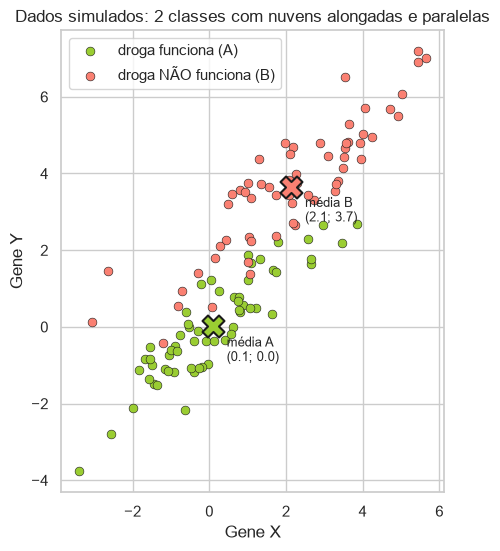

In [21]:
# ---------------------------------------------------------------
# Visualização dos dados simulados: cada classe com uma cor,
# e a média de cada classe marcada com um "X" grande
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 6))

for classe, cor, nome in [(0, "yellowgreen", "droga funciona (A)"),
                          (1, "salmon",      "droga NÃO funciona (B)")]:
    pts = X2[y2 == classe]                      # só as amostras desta classe
    ax.scatter(pts[:, 0], pts[:, 1], c=cor, s=40, edgecolor="k", lw=0.4, label=nome)

    media = pts.mean(axis=0)                    # média da classe (centro da nuvem)
    ax.scatter(*media, marker="X", s=250, c=cor, edgecolor="k", lw=1.5, zorder=5)
    ax.annotate(f"média {nome[-2]}\n({media[0]:.1f}; {media[1]:.1f})", media,
                xytext=(10, -25), textcoords="offset points", fontsize=9)

ax.set(xlabel="Gene X", ylabel="Gene Y", aspect="equal",
       title="Dados simulados: 2 classes com nuvens alongadas e paralelas")
ax.legend(loc="upper left")
plt.show()

In [22]:
def razao_fisher(z, y):
    # Calcula d² / (s1² + s2²) para dados JÁ projetados em uma reta (z é 1D)
    z0, z1 = z[y == 0], z[y == 1]
    d2 = (z0.mean() - z1.mean()) ** 2
    return d2 / (z0.var(ddof=1) + z1.var(ddof=1))

m0, m1 = X2[y2 == 0].mean(axis=0), X2[y2 == 1].mean(axis=0)   # médias de cada classe

# (1) Direção que SÓ maximiza d: a reta que liga as duas médias
w_d = (m1 - m0) / np.linalg.norm(m1 - m0)

# (2) Direção do PCA: PC1 (não usa os rótulos!)
w_pca = PCA(n_components=1).fit(X2).components_[0]

# (3) Direção do LDA. Fórmula clássica de Fisher: w ∝ Sw⁻¹ (m1 − m0),
#     onde Sw é a matriz de dispersão DENTRO das classes.
Sw = np.cov(X2[y2 == 0].T) + np.cov(X2[y2 == 1].T)
w_lda = np.linalg.solve(Sw, m1 - m0)
w_lda = w_lda / np.linalg.norm(w_lda)          # normaliza para comprimento 1

direcoes = {"Só maximiza d": w_d, "PCA (PC1)": w_pca, "LDA (LD1)": w_lda}
for nome, w in direcoes.items():
    print(f"{nome:15s} direção = {w.round(2)}   razão de Fisher J = {razao_fisher(X2 @ w, y2):6.2f}")

Só maximiza d   direção = [0.49 0.87]   razão de Fisher J =   1.94
PCA (PC1)       direção = [0.63 0.78]   razão de Fisher J =   1.74
LDA (LD1)       direção = [-0.53  0.85]   razão de Fisher J =   4.77


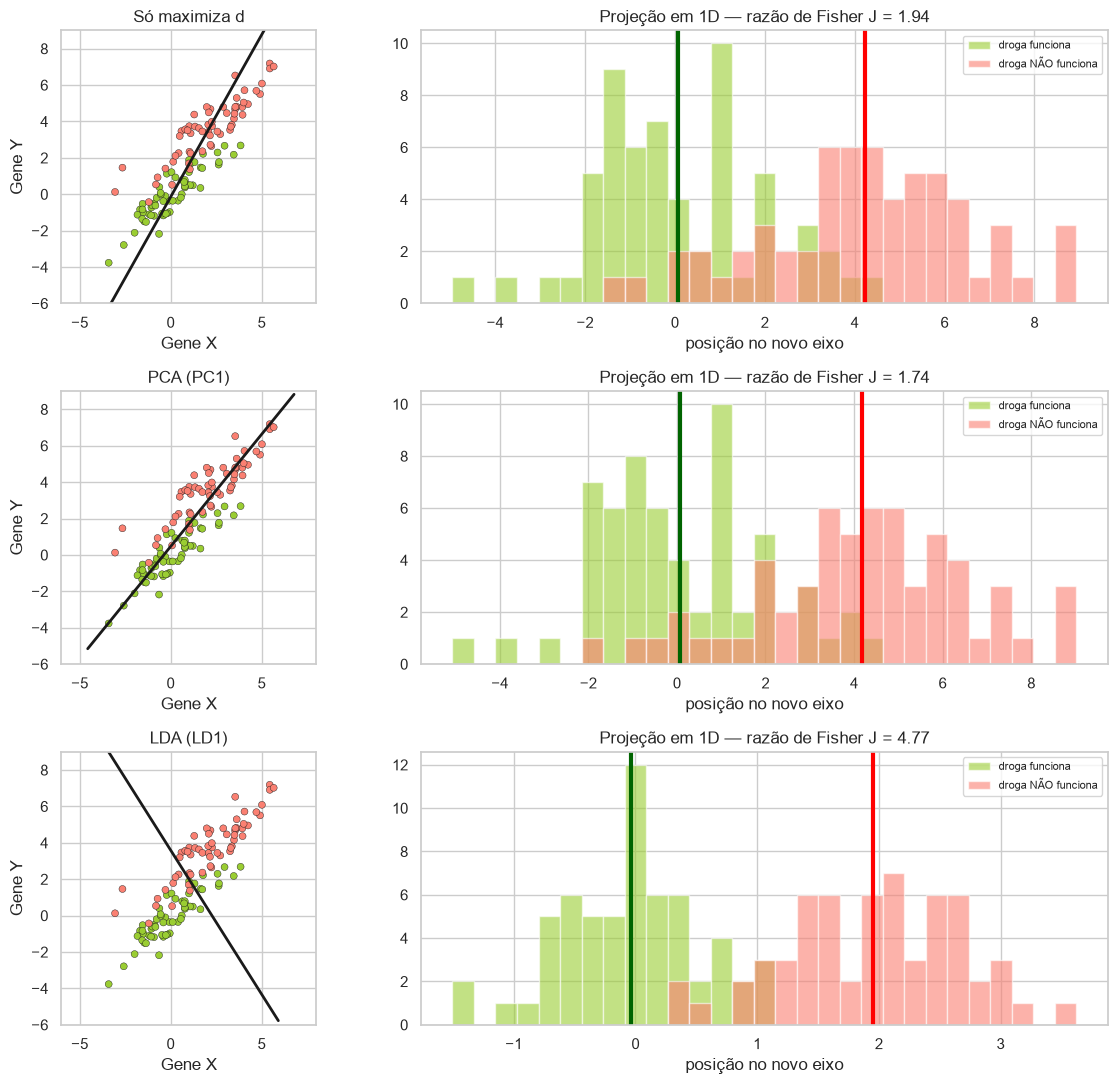

In [23]:
# ---------------------------------------------------------------
# Visualização: cada linha da figura é uma direção.
# Esquerda: a reta sobre os dados 2D.  Direita: os dados projetados (1D).
# ---------------------------------------------------------------
cores = np.array(["yellowgreen", "salmon"])
centro = X2.mean(axis=0)

fig, axes = plt.subplots(3, 2, figsize=(12, 11), gridspec_kw={"width_ratios": [1, 1.4]})
for linha, (nome, w) in enumerate(direcoes.items()):
    ax2d, ax1d = axes[linha]

    # --- Painel 2D ---
    ax2d.scatter(X2[:, 0], X2[:, 1], c=cores[y2], s=25, edgecolor="k", lw=0.3)
    t = np.linspace(-9, 9, 2)
    ax2d.plot(centro[0] + t * w[0], centro[1] + t * w[1], "k-", lw=2)
    ax2d.set(title=nome, xlabel="Gene X", ylabel="Gene Y", xlim=(-6, 8), ylim=(-6, 9), aspect="equal")

    # --- Painel 1D: histogramas das projeções ---
    z = X2 @ w
    bins = np.linspace(z.min(), z.max(), 30)
    ax1d.hist(z[y2 == 0], bins=bins, alpha=.6, color="yellowgreen", label="droga funciona")
    ax1d.hist(z[y2 == 1], bins=bins, alpha=.6, color="salmon", label="droga NÃO funciona")
    for k, cor in [(0, "darkgreen"), (1, "red")]:
        ax1d.axvline(z[y2 == k].mean(), color=cor, lw=3)      # médias projetadas (as barrinhas do slide)
    ax1d.set(title=f"Projeção em 1D — razão de Fisher J = {razao_fisher(z, y2):.2f}",
             xlabel="posição no novo eixo")
    ax1d.legend(fontsize=8)
plt.tight_layout(); plt.show()

**O que observar:**

- **Só d:** as médias ficam distantes, mas cada classe fica muito "espalhada" na projeção → as classes se **sobrepõem** (exatamente o slide *"...mas a separação entre os grupos não seria boa"*).
- **PCA:** escolhe a direção ao longo da qual as nuvens são alongadas, pois é ali que está a maior variância. Como o PCA **não olha os rótulos**, essa direção pode ser péssima para separar as classes.
- **LDA:** as médias podem até ficar *mais próximas* em valor absoluto, mas como cada classe fica **compacta**, a separação é muito melhor (maior *J*).

Por fim, vamos conferir que o `LinearDiscriminantAnalysis` do scikit-learn encontra a mesma direção da fórmula de Fisher.

In [24]:
lda_toy = LinearDiscriminantAnalysis(n_components=1).fit(X2, y2)
w_sk = lda_toy.scalings_[:, 0] / np.linalg.norm(lda_toy.scalings_[:, 0])
print("Direção do LDA (fórmula de Fisher):", w_lda.round(3))
print("Direção do LDA (scikit-learn)     :", w_sk.round(3), " (pode vir com sinal trocado)")
print("Número máximo de eixos do LDA = nº de classes − 1 =", len(np.unique(y2)) - 1)

Direção do LDA (fórmula de Fisher): [-0.534  0.846]
Direção do LDA (scikit-learn)     : [-0.534  0.846]  (pode vir com sinal trocado)
Número máximo de eixos do LDA = nº de classes − 1 = 1


---
## Parte 3 — O conjunto de dados real: TCGA Pan-Cancer (RNA-Seq)

Agora vamos para dados reais e **grandes**.

**Gene Expression Cancer RNA-Seq** (UCI Machine Learning Repository, ID 401)

- Origem: projeto **TCGA** (*The Cancer Genome Atlas*), iniciativa Pan-Cancer, sequenciamento Illumina HiSeq.
- **801 amostras** de tumor (linhas) × **20.531 genes** (colunas).
- Cada amostra pertence a um de **5 tipos de câncer**:

| Sigla | Tipo de tumor |
|---|---|
| BRCA | carcinoma invasivo de mama |
| KIRC | carcinoma renal de células claras |
| COAD | adenocarcinoma de cólon |
| LUAD | adenocarcinoma de pulmão |
| PRAD | adenocarcinoma de próstata |

- Os nomes dos genes foram **anonimizados** no arquivo (`gene_0`, `gene_1`, ...). Isso não atrapalha o nosso estudo de PCA/LDA, mas significa que não poderemos interpretar biologicamente quais genes aparecem nos *loadings*.
- Página: https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq

> Repare na situação típica de bioinformática: **p (genes) ≫ n (amostras)**. Temos ~25 vezes mais variáveis do que amostras! Isso será crucial na Parte 5.

A célula abaixo baixa o arquivo (~70 MB compactado) e descompacta. Leva cerca de 1 minuto no Colab.

In [25]:
# ---------------------------------------------------------------
# Download e extração dos dados (só baixa se ainda não existir)
# ---------------------------------------------------------------
URL = "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip"
ARQ_ZIP = "gene+expression+cancer+rna+seq.zip"

if not os.path.exists(ARQ_ZIP):
    print("Baixando os dados do UCI... (pode levar ~1 minuto)")
    urllib.request.urlretrieve(URL, ARQ_ZIP)

# O .zip contém um .tar.gz, que por sua vez contém data.csv e labels.csv
with zipfile.ZipFile(ARQ_ZIP) as z:
    z.extractall(".")
for tgz in glob.glob("*.tar.gz"):
    with tarfile.open(tgz) as t:
        try:
            t.extractall(".", filter="data")   # Python >= 3.12: extração segura
        except TypeError:
            t.extractall(".")                  # versões antigas do Python

arq_dados  = glob.glob("**/data.csv",   recursive=True)[0]
arq_rotulo = glob.glob("**/labels.csv", recursive=True)[0]
print("Arquivos encontrados:", arq_dados, "|", arq_rotulo)

Baixando os dados do UCI... (pode levar ~1 minuto)
Arquivos encontrados: TCGA-PANCAN-HiSeq-801x20531\data.csv | TCGA-PANCAN-HiSeq-801x20531\labels.csv


In [26]:
# ---------------------------------------------------------------
# Leitura (index_col=0: a primeira coluna é o identificador da amostra)
# ---------------------------------------------------------------
t0 = time.time()
dados   = pd.read_csv(arq_dados, index_col=0)
rotulos = pd.read_csv(arq_rotulo, index_col=0)["Class"]
print(f"Leitura concluída em {time.time() - t0:.1f} s")

# Conferência: as amostras estão na mesma ordem nos dois arquivos?
assert (dados.index == rotulos.index).all()

print("Formato da matriz de expressão (amostras × genes):", dados.shape)
display(dados.iloc[:5, :8])   # primeiras 5 amostras e 8 genes

Leitura concluída em 4.8 s
Formato da matriz de expressão (amostras × genes): (801, 20531)


,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595
sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882
sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982


,nº de amostras
Class,
BRCA,300
KIRC,146
LUAD,141
PRAD,136
COAD,78


Valor mínimo: 0.00 | máximo: 20.78 | mediana: 7.61
Fração de zeros na matriz: 14.2%


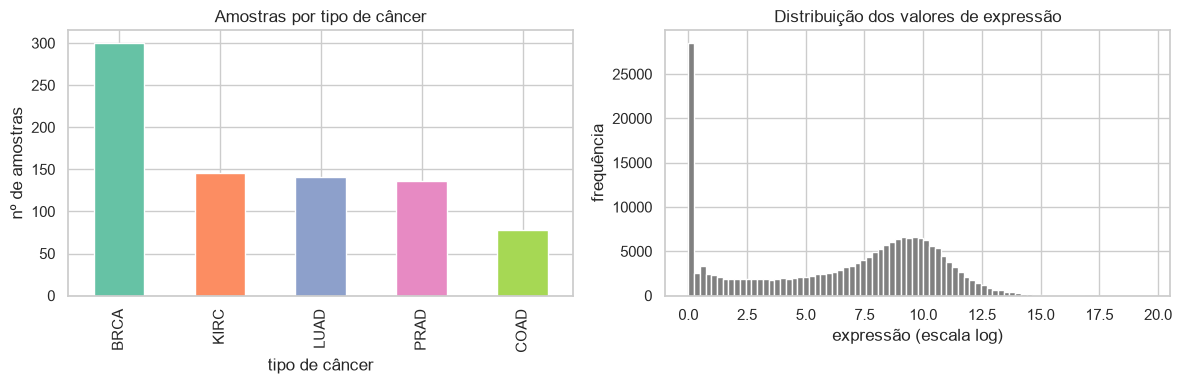

In [27]:
# ---------------------------------------------------------------
# Exploração rápida
# ---------------------------------------------------------------
# 1) Quantas amostras de cada tipo de câncer?
contagem = rotulos.value_counts()
display(contagem.to_frame("nº de amostras"))

# 2) Faixa de valores: os dados já vêm normalizados e em escala logarítmica
print(f"Valor mínimo: {dados.values.min():.2f} | máximo: {dados.values.max():.2f} | "
      f"mediana: {np.median(dados.values):.2f}")
print(f"Fração de zeros na matriz: {100 * (dados.values == 0).mean():.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
contagem.plot.bar(ax=ax[0], color=sns.color_palette("Set2", len(contagem)))
ax[0].set(title="Amostras por tipo de câncer", xlabel="tipo de câncer", ylabel="nº de amostras")
# Histograma de uma amostra aleatória de valores (para não desenhar 16 milhões de números)
amostra_valores = np.random.choice(dados.values.ravel(), 200_000, replace=False)
ax[1].hist(amostra_valores, bins=80, color="gray")
ax[1].set(title="Distribuição dos valores de expressão", xlabel="expressão (escala log)", ylabel="frequência")
plt.tight_layout(); plt.show()

### Pré-processamento

1. **Remover genes constantes** (variância zero, ex.: genes com expressão zero em todas as amostras). Eles não carregam nenhuma informação e, no PCA, não contribuem para nenhuma componente.
2. **Escala:** os dados já estão em escala logarítmica, que é a forma usual de aplicar PCA em RNA-Seq (vimos na aula de normalização que contagens brutas têm variância que cresce com a média). Vamos apenas **centralizar** (o `PCA` do scikit-learn faz isso sozinho), sem padronizar cada gene para variância 1.

> 💬 **Discussão:** padronizar (z-score) daria o mesmo peso a todos os genes, inclusive aos que quase não variam (ruído). Sem padronizar, genes mais variáveis pesam mais. Ambas as escolhas aparecem na literatura; o exercício 2 pede para você comparar.

In [28]:
variancias = dados.var(axis=0)
genes_constantes = (variancias == 0).sum()
X = dados.loc[:, variancias > 0]          # mantém só genes com alguma variação
y = rotulos.copy()

print(f"Genes constantes removidos: {genes_constantes}")
print(f"Matriz final: {X.shape[0]} amostras × {X.shape[1]} genes")

# Paleta fixa: cada tipo de câncer terá sempre a mesma cor em todos os gráficos
classes = sorted(y.unique())
paleta = dict(zip(classes, sns.color_palette("Set2", len(classes))))

Genes constantes removidos: 267
Matriz final: 801 amostras × 20264 genes


---
## Parte 4 — PCA nos dados reais

Exatamente o mesmo procedimento do exemplo dos ratos, só que agora com **~20 mil genes**:

1. centralizar cada gene;
2. encontrar PC1 (direção de maior variância), PC2 (perpendicular à PC1, com a 2ª maior variância), e assim por diante — tudo de uma vez via **SVD**;
3. projetar as amostras.

Com *n* = 801 amostras, existem no máximo 800 PCs úteis (*n* − 1). Vamos calcular as **50 primeiras**.

> **Importante:** o PCA **não usa** os rótulos `y`. As cores nos gráficos abaixo são colocadas **depois**, só para nós, humanos, conferirmos se a estrutura encontrada tem relação com o tipo de câncer.

In [29]:
t0 = time.time()
pca = PCA(n_components=50, random_state=SEED)
Z_pca = pca.fit_transform(X)          # coordenadas das 801 amostras nas 50 PCs (equivale a U·Σ)
print(f"PCA calculado em {time.time() - t0:.1f} s")
print("Formato das projeções:", Z_pca.shape)

ev = 100 * pca.explained_variance_ratio_
for i in range(5):
    print(f"PC{i+1}: {ev[i]:5.2f}% da variação   (acumulado: {ev[:i+1].sum():5.2f}%)")

PCA calculado em 1.5 s
Formato das projeções: (801, 50)
PC1: 15.84% da variação   (acumulado: 15.84%)
PC2: 10.50% da variação   (acumulado: 26.34%)
PC3:  9.47% da variação   (acumulado: 35.81%)
PC4:  6.50% da variação   (acumulado: 42.32%)
PC5:  3.62% da variação   (acumulado: 45.93%)


### Gráfico de variação explicada (*scree plot*)

Como no slide *"PC1 e PC2 são responsáveis por 94% da variação nos dados"*: um gráfico de barras com a % de variação de cada PC. Ele nos ajuda a decidir **quantas PCs** valem a pena manter.

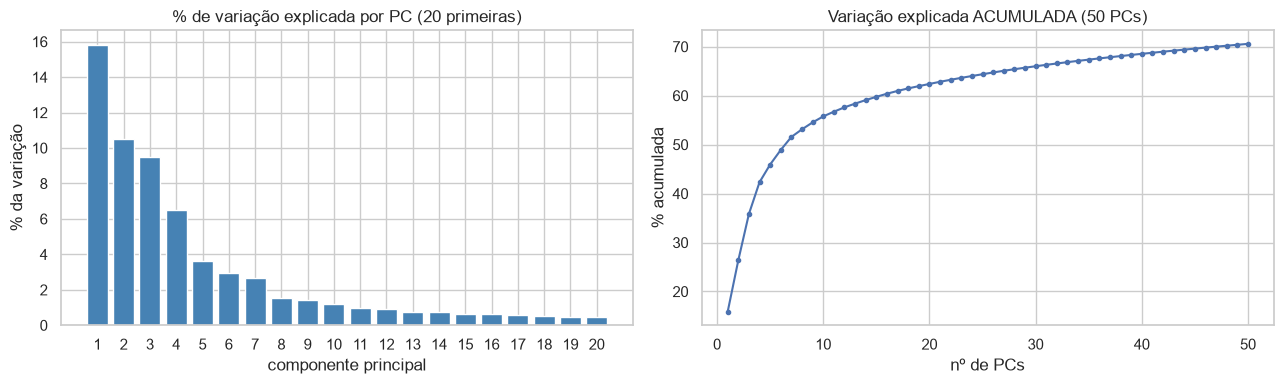

Com 2 PCs explicamos 26.3% da variação total de ~20 mil genes.
Com 50 PCs explicamos 70.6%.


In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, 21), ev[:20], color="steelblue")
ax[0].set(title="% de variação explicada por PC (20 primeiras)", xlabel="componente principal", ylabel="% da variação")
ax[0].set_xticks(range(1, 21))

ax[1].plot(range(1, 51), np.cumsum(ev), "o-", ms=3)
ax[1].set(title="Variação explicada ACUMULADA (50 PCs)", xlabel="nº de PCs", ylabel="% acumulada")
plt.tight_layout(); plt.show()

print(f"Com 2 PCs explicamos {ev[:2].sum():.1f}% da variação total de ~20 mil genes.")
print(f"Com 50 PCs explicamos {ev.sum():.1f}%.")

### Projeção das amostras em PC1 × PC2 (e PC1 × PC3)

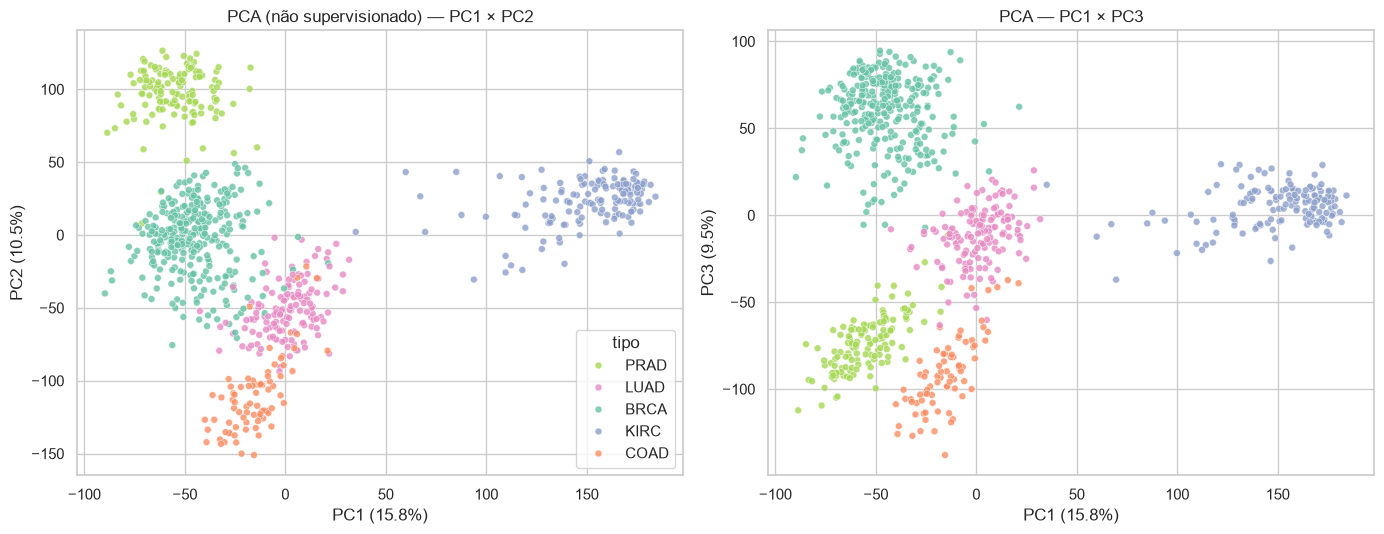

In [31]:
df_pca = pd.DataFrame(Z_pca[:, :3], columns=["PC1", "PC2", "PC3"], index=X.index)
df_pca["tipo"] = y

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="tipo", palette=paleta, s=25, alpha=.8, ax=ax[0])
ax[0].set(title="PCA (não supervisionado) — PC1 × PC2",
          xlabel=f"PC1 ({ev[0]:.1f}%)", ylabel=f"PC2 ({ev[1]:.1f}%)")
sns.scatterplot(data=df_pca, x="PC1", y="PC3", hue="tipo", palette=paleta, s=25, alpha=.8, ax=ax[1], legend=False)
ax[1].set(title="PCA — PC1 × PC3", xlabel=f"PC1 ({ev[0]:.1f}%)", ylabel=f"PC3 ({ev[2]:.1f}%)")
plt.tight_layout(); plt.show()

**Para pensar:**

- Sem ver nenhum rótulo, o PCA já agrupa amostras do mesmo tipo de câncer? Quais tipos ficam bem isolados e quais se sobrepõem?
- Por que tipos de tumor de **tecidos diferentes** (rim, próstata, mama...) tenderiam a aparecer separados? *(Dica: grande parte da variação na expressão gênica vem do tecido de origem.)*
- Olhe PC1 × PC3: algum grupo que estava sobreposto em PC1 × PC2 se separa usando a PC3? Lembre-se: **a PC3 também carrega informação**, ela só explica menos variação.

### *Loading scores*: quais genes "conduzem" a PC1?

Assim como no exemplo dos ratos (PC1 = 0,97 × Gene 1 + 0,24 × Gene 2), cada PC aqui é uma **combinação linear de ~20 mil genes**. Os genes com maior |loading| são os que mais influenciam aquela PC.

Comprimento do vetor de loadings da PC1: 1.0


,PC1,PC2
Top 10 genes da PC1,,
gene_3439,0.0555,0.0030
gene_6733,0.0554,0.0066
gene_439,-0.0544,-0.0118
gene_219,0.0535,0.0142
gene_1510,0.0524,0.0127
gene_16132,0.0523,0.0121
gene_16169,0.0519,0.0167
gene_220,0.0516,0.0129
gene_19153,0.0515,-0.0030


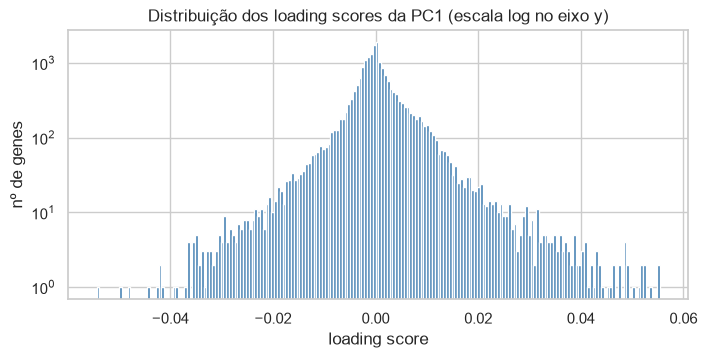

In [32]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])

# Conferência: o vetor de loadings tem comprimento 1 (vetor unitário), como na aula
print("Comprimento do vetor de loadings da PC1:", round(np.linalg.norm(loadings["PC1"]), 4))

top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(10).index
display(loadings.loc[top_pc1].round(4).rename_axis("Top 10 genes da PC1"))

# Distribuição de todos os loadings: a maioria dos genes contribui quase nada
plt.figure(figsize=(8, 3.5))
plt.hist(loadings["PC1"], bins=200, color="steelblue")
plt.yscale("log")
plt.title("Distribuição dos loading scores da PC1 (escala log no eixo y)")
plt.xlabel("loading score"); plt.ylabel("nº de genes"); plt.show()

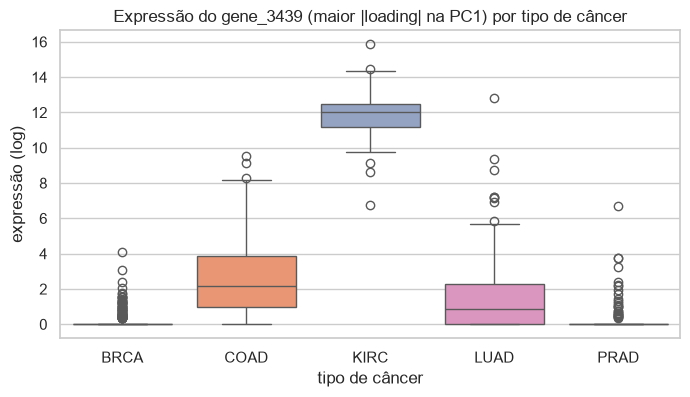

In [33]:
# Expressão do gene de maior |loading| na PC1, separada por tipo de câncer
gene_top = top_pc1[0]
plt.figure(figsize=(8, 4))
sns.boxplot(x=y, y=X[gene_top], order=classes, hue=y, palette=paleta, legend=False)
plt.title(f"Expressão do {gene_top} (maior |loading| na PC1) por tipo de câncer")
plt.xlabel("tipo de câncer"); plt.ylabel("expressão (log)"); plt.show()

### Usar só algumas PCs é uma "boa aproximação"?

Nos slides: *"Usar apenas PC1 e PC2 já dá uma boa aproximação do gráfico 3D"*. Podemos medir isso: projetamos os dados em *k* PCs e **reconstruímos** a matriz original. Quanto menor o erro, mais informação as *k* PCs preservam.

In [34]:
erros = []
ks = [1, 2, 5, 10, 20, 50]
for k in ks:
    # Reconstrução: coordenadas nas k PCs × loadings + média
    X_rec = Z_pca[:, :k] @ pca.components_[:k] + pca.mean_
    erro_rel = np.linalg.norm(X.values - X_rec) ** 2 / np.linalg.norm(X.values - pca.mean_) ** 2
    erros.append(100 * erro_rel)
    print(f"k = {k:2d} PCs -> variação NÃO capturada = {100*erro_rel:5.1f}%  (= 100% - acumulado do scree plot)")

k =  1 PCs -> variação NÃO capturada =  84.2%  (= 100% - acumulado do scree plot)
k =  2 PCs -> variação NÃO capturada =  73.7%  (= 100% - acumulado do scree plot)
k =  5 PCs -> variação NÃO capturada =  54.1%  (= 100% - acumulado do scree plot)
k = 10 PCs -> variação NÃO capturada =  44.2%  (= 100% - acumulado do scree plot)
k = 20 PCs -> variação NÃO capturada =  37.6%  (= 100% - acumulado do scree plot)
k = 50 PCs -> variação NÃO capturada =  29.4%  (= 100% - acumulado do scree plot)


---
## Parte 5 — LDA nos dados reais

Agora usamos os **rótulos** (`y`). O LDA procura os eixos que **maximizam a separação entre os 5 tipos de câncer**:

- distância das médias de cada classe até o **ponto central geral** (numerador);
- variância **dentro** de cada classe (denominador).

Com **5 classes**, o LDA produz no máximo **5 − 1 = 4 eixos** (LD1 a LD4). Lembre do slide: *k* médias definem um espaço de *k* − 1 dimensões.

### ⚠️ Cuidado: um método supervisionado precisa ser avaliado em dados novos

Como o LDA **aprende com os rótulos**, olhar apenas o gráfico das amostras usadas no ajuste pode enganar. Por isso vamos separar:

- **75% treino** (o LDA aprende os eixos);
- **25% teste** (amostras que o LDA nunca viu, só projetadas nos eixos já aprendidos).

`stratify=y` garante a mesma proporção de cada câncer nos dois conjuntos.

In [35]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("Treino:", X_tr.shape, "| Teste:", X_te.shape)
print("Proporções no treino:\n", y_tr.value_counts(normalize=True).round(3))

Treino: (600, 20264) | Teste: (201, 20264)
Proporções no treino:
 Class
BRCA    0.375
KIRC    0.182
LUAD    0.177
PRAD    0.170
COAD    0.097
Name: proportion, dtype: float64


### 5.1 — LDA "ingênuo" com todos os ~20 mil genes

Primeiro, aplicamos o LDA diretamente em todos os genes. Lembre: temos ~600 amostras de treino e ~20 mil genes (**p ≫ n**).

In [36]:
t0 = time.time()
lda_full = LinearDiscriminantAnalysis(n_components=4)   # svd: solver padrão, funciona mesmo com p > n
lda_full.fit(X_tr, y_tr)
print(f"LDA ajustado em {time.time() - t0:.1f} s")

Z_tr_full = lda_full.transform(X_tr)   # projeção do TREINO
Z_te_full = lda_full.transform(X_te)   # projeção do TESTE (amostras novas)

print("Variação ENTRE classes explicada por cada LD (%):",
      (100 * lda_full.explained_variance_ratio_).round(1))
print(f"Acurácia no TREINO: {lda_full.score(X_tr, y_tr):.3f}")
print(f"Acurácia no TESTE : {lda_full.score(X_te, y_te):.3f}")

LDA ajustado em 7.5 s
Variação ENTRE classes explicada por cada LD (%): [37.5 27.2 21.9 13.4]
Acurácia no TREINO: 0.998
Acurácia no TESTE : 0.985


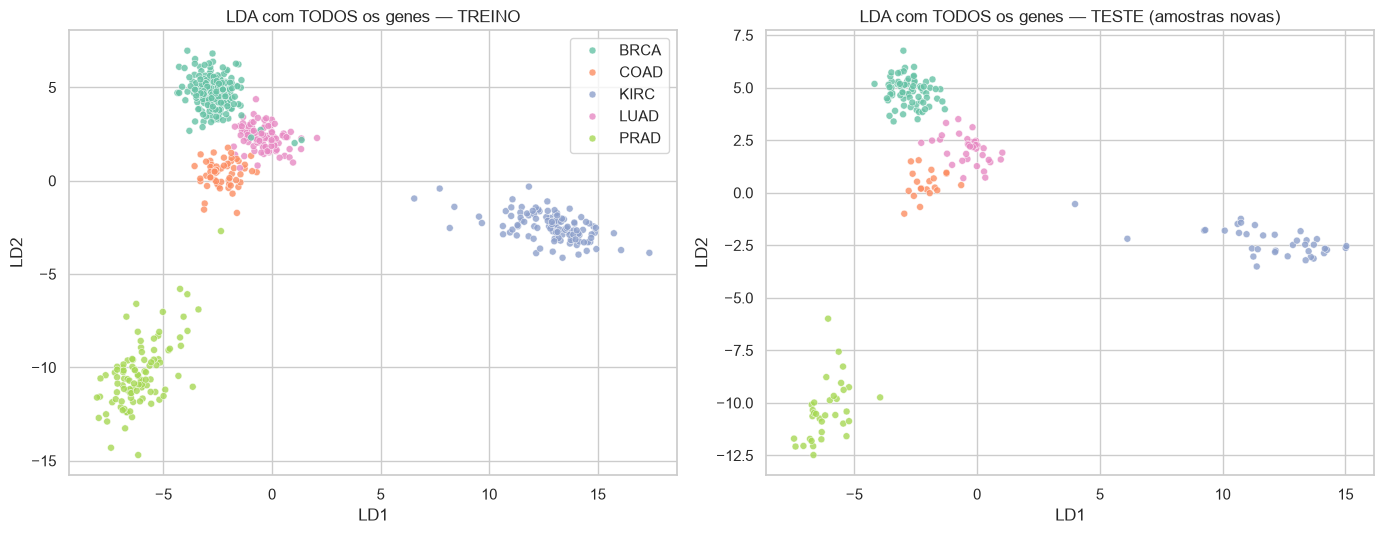

Silhueta em LD1 × LD2:
treino    0.664
teste     0.683


In [37]:
def plot_ld(Z, rot, titulo, ax, legenda=True):
    # Desenha LD1 × LD2 colorido por tipo de câncer
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=rot.values, hue_order=classes, palette=paleta,
                    s=25, alpha=.8, ax=ax, legend=legenda)
    ax.set(title=titulo, xlabel="LD1", ylabel="LD2")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
plot_ld(Z_tr_full, y_tr, "LDA com TODOS os genes — TREINO", ax[0])
plot_ld(Z_te_full, y_te, "LDA com TODOS os genes — TESTE (amostras novas)", ax[1], legenda=False)
plt.tight_layout(); plt.show()

# Quão bem separadas ficaram as classes? Usamos a SILHUETA (de -1 a 1) em LD1 × LD2:
# compara a distância de cada amostra ao seu grupo com a distância ao grupo vizinho.
# Ela não depende da escala dos eixos, então podemos comparar treino e teste.
def silhuetas(Z_tr, Z_te):
    return pd.Series({"treino": silhouette_score(Z_tr[:, :2], y_tr),
                      "teste":  silhouette_score(Z_te[:, :2], y_te)}).round(3)

print("Silhueta em LD1 × LD2:")
print(silhuetas(Z_tr_full, Z_te_full).to_string())

**O que observar:** compare as acurácias e as silhuetas de **treino** e de **teste**, e os dois gráficos.

- Se o treino parecer **mais bem separado** do que o teste (silhueta de treino maior), o gráfico de treino está sendo **otimista demais**: é o sinal de **sobreajuste** (*overfitting*).
- Neste conjunto de dados, os 5 tipos de tumor vêm de **tecidos muito diferentes**, então mesmo o LDA "ingênuo" pode ir bem no teste. Além disso, o solver padrão do scikit-learn (`svd`) descarta internamente as direções em que não há variação dentro das classes, o que atenua o problema.

Para enxergar o perigo de forma inequívoca, vamos fazer um **experimento controlado**.

### 5.2 — Experimento: o LDA "enxerga" grupos até em rótulos aleatórios

Ideia:

1. Reduzimos os dados com PCA para *k* componentes e aplicamos o LDA nessas *k* variáveis. Vamos variar *k* de 5 até quase o número de amostras de treino (~600).
2. Fazemos isso com os **rótulos verdadeiros** e com **rótulos embaralhados aleatoriamente** — que **não têm nenhum significado biológico**. Um bom método deveria dizer: *"não há separação nenhuma aqui"*.

Lembre: com ~600 amostras de treino e *k* próximo de 600 variáveis, a matriz de variância **dentro** das classes fica quase impossível de estimar (temos quase tantos parâmetros quanto amostras).

In [38]:
# Rótulos embaralhados: mesma proporção de classes, mas sem relação nenhuma com a expressão gênica
rng_perm = np.random.default_rng(SEED)
y_tr_rand = pd.Series(rng_perm.permutation(y_tr.values), index=y_tr.index)
y_te_rand = pd.Series(rng_perm.permutation(y_te.values), index=y_te.index)

# Para economizar tempo, calculamos o PCA UMA vez (no treino) com muitas componentes
# e depois usamos só as k primeiras colunas em cada rodada.
k_max = X_tr.shape[0] - 10                       # um pouco abaixo do nº de amostras de treino
pca_big = PCA(n_components=k_max, random_state=SEED).fit(X_tr)
P_tr, P_te = pca_big.transform(X_tr), pca_big.transform(X_te)

linhas = []
for k in [5, 20, 50, 100, 200, 400, 500, k_max]:
    for nome_rot, ytr_, yte_ in [("verdadeiros", y_tr, y_te), ("aleatórios", y_tr_rand, y_te_rand)]:
        lda_k = LinearDiscriminantAnalysis(n_components=2).fit(P_tr[:, :k], ytr_)
        linhas.append({
            "k": k, "rótulos": nome_rot,
            "acurácia treino": lda_k.score(P_tr[:, :k], ytr_),
            "acurácia teste":  lda_k.score(P_te[:, :k], yte_),
            "silhueta treino": silhouette_score(lda_k.transform(P_tr[:, :k]), ytr_),
            "silhueta teste":  silhouette_score(lda_k.transform(P_te[:, :k]), yte_)})
exp = pd.DataFrame(linhas)
display(exp.round(3).pivot(index="k", columns="rótulos"))

acurácia treino             acurácia teste              \
rótulos      aleatórios verdadeiros     aleatórios verdadeiros   
k                                                                
5                 0.375       0.995          0.373       0.980   
20                0.407       1.000          0.348       0.990   
50                0.443       1.000          0.313       0.995   
100               0.528       1.000          0.269       0.995   
200               0.715       1.000          0.279       1.000   
400               0.940       1.000          0.303       1.000   
500               0.983       1.000          0.323       1.000   
590               0.998       1.000          0.289       0.990   

        silhueta treino             silhueta teste              
rótulos      aleatórios verdadeiros     aleatórios verdadeiros  
k                                                               
5                -0.055       0.645         -0.077       0.620  
20               -0.069       0.763         -0.082       0.741  
50               -0.080       0.760         -0.088       0.762  
100              -0.045       0.759         -0.087       0.737  
200              -0.033       0.826         -0.066       0.750  
400               0.251       0.944         -0.101       0.787  
500               0.441       0.955         -0.108       0.687  
590               0.864       0.995         -0.091       0.683

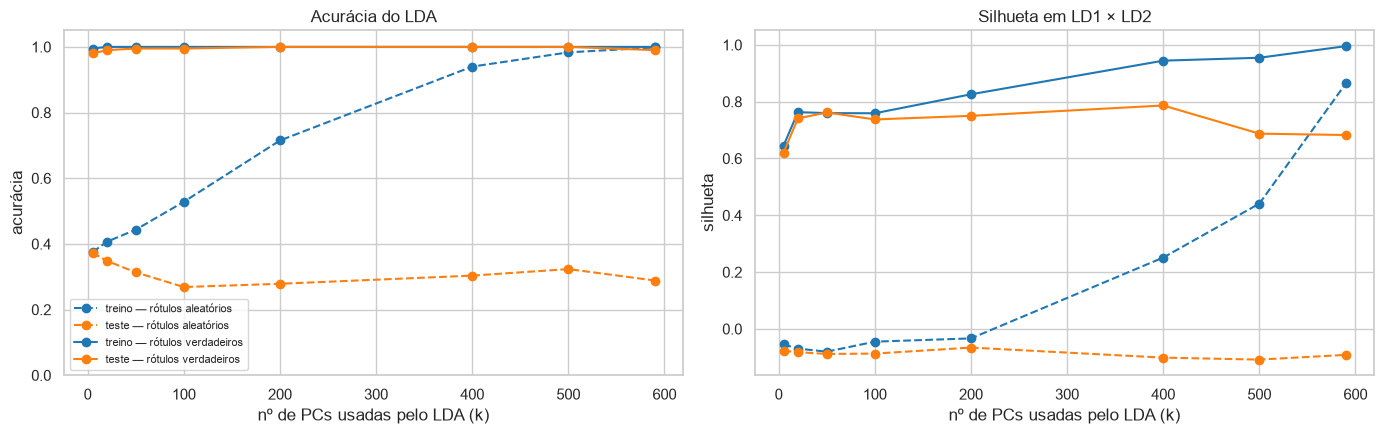

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
estilos = {"verdadeiros": "-", "aleatórios": "--"}
for nome_rot, df_ in exp.groupby("rótulos"):
    for metrica, cor in [("treino", "tab:blue"), ("teste", "tab:orange")]:
        ax[0].plot(df_["k"], df_[f"acurácia {metrica}"], estilos[nome_rot], marker="o", color=cor,
                   label=f"{metrica} — rótulos {nome_rot}")
        ax[1].plot(df_["k"], df_[f"silhueta {metrica}"], estilos[nome_rot], marker="o", color=cor,
                   label=f"{metrica} — rótulos {nome_rot}")
ax[0].set(title="Acurácia do LDA", xlabel="nº de PCs usadas pelo LDA (k)", ylabel="acurácia", ylim=(0, 1.05))
ax[1].set(title="Silhueta em LD1 × LD2", xlabel="nº de PCs usadas pelo LDA (k)", ylabel="silhueta")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

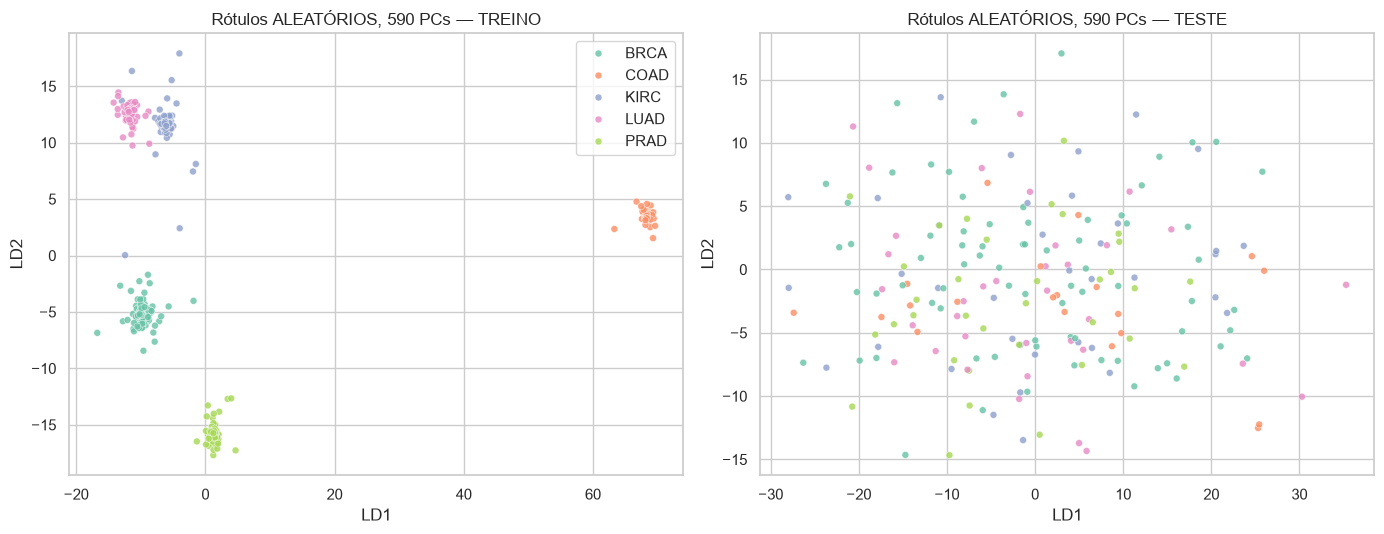

In [40]:
# O caso mais extremo: rótulos ALEATÓRIOS e k quase igual ao nº de amostras
lda_rand = LinearDiscriminantAnalysis(n_components=2).fit(P_tr, y_tr_rand)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
plot_ld(lda_rand.transform(P_tr), y_tr_rand, f"Rótulos ALEATÓRIOS, {k_max} PCs — TREINO", ax[0])
plot_ld(lda_rand.transform(P_te), y_te_rand, f"Rótulos ALEATÓRIOS, {k_max} PCs — TESTE", ax[1], legenda=False)
plt.tight_layout(); plt.show()

**O que esse experimento mostra:**

- Com **rótulos aleatórios** e *k* grande, o LDA "encontra" grupos lindamente separados no **treino** — a partir de puro ruído! No **teste**, a acurácia fica no nível do acaso e não há separação nenhuma.
- Com os **rótulos verdadeiros**, a separação no teste é real, mas a silhueta de treino tende a crescer com *k* mais do que a de teste: o treino fica cada vez mais otimista.
- **Lição:** um gráfico de LDA feito com as mesmas amostras usadas para ajustá-lo **não é evidência** de que os grupos são separáveis. Sempre avalie em dados novos (ou com validação cruzada).

### 5.3 — Solução clássica: PCA primeiro (poucas PCs), LDA depois

Uma estratégia muito usada em bioinformática é **reduzir a dimensionalidade com PCA** (não supervisionado) e aplicar o **LDA em poucas PCs** — por exemplo, 50 — bem menos do que o número de amostras.

Usamos um `Pipeline` para garantir que o **PCA seja ajustado só no treino** (senão haveria vazamento de informação do teste).

PCA(50)+LDA — acurácia TREINO: 1.000 | TESTE: 1.000


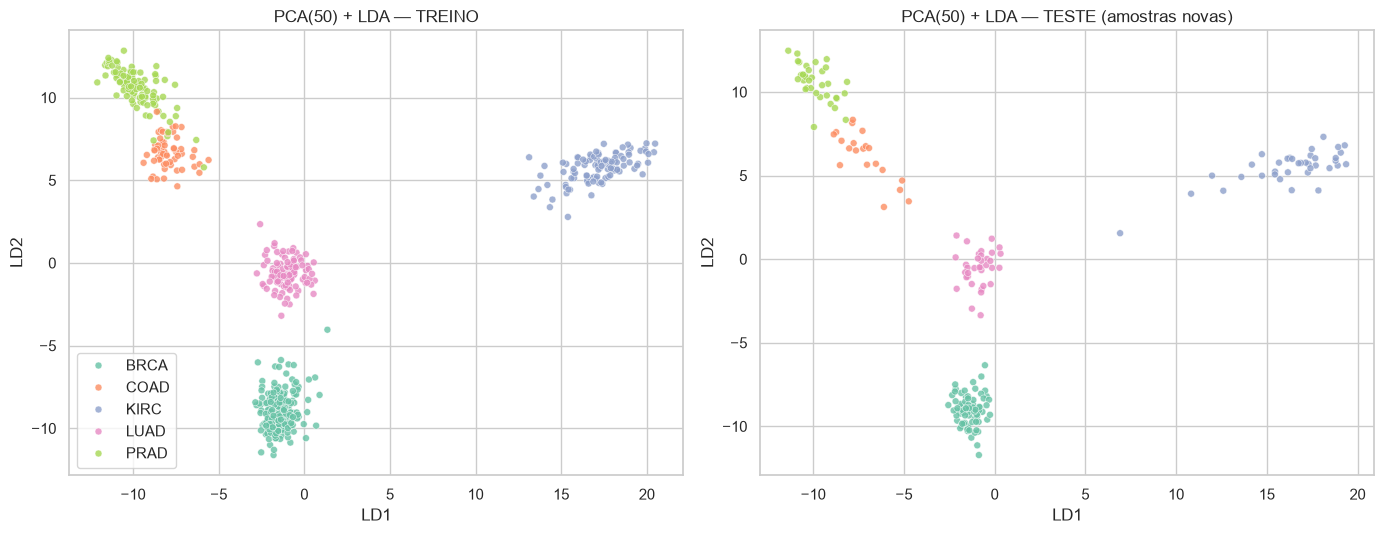

Silhueta em LD1 × LD2:
treino    0.765
teste     0.763


In [41]:
pca_lda = make_pipeline(PCA(n_components=50, random_state=SEED),
                        LinearDiscriminantAnalysis(n_components=4))
pca_lda.fit(X_tr, y_tr)

Z_tr_pl = pca_lda.transform(X_tr)
Z_te_pl = pca_lda.transform(X_te)
print(f"PCA(50)+LDA — acurácia TREINO: {pca_lda.score(X_tr, y_tr):.3f} | TESTE: {pca_lda.score(X_te, y_te):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
plot_ld(Z_tr_pl, y_tr, "PCA(50) + LDA — TREINO", ax[0])
plot_ld(Z_te_pl, y_te, "PCA(50) + LDA — TESTE (amostras novas)", ax[1], legenda=False)
plt.tight_layout(); plt.show()

print("Silhueta em LD1 × LD2:")
print(silhuetas(Z_tr_pl, Z_te_pl).to_string())

Com poucas PCs, o gráfico de treino e o de teste devem ser **parecidos**: o que vemos no treino passa a ser uma estimativa honesta do que acontece com amostras novas.

### 5.4 — O LDA também é um classificador

Como visto no sumário da Aula 11, o LDA serve **tanto para reduzir dimensionalidade quanto para classificar**. Vamos ver a matriz de confusão no conjunto de teste.

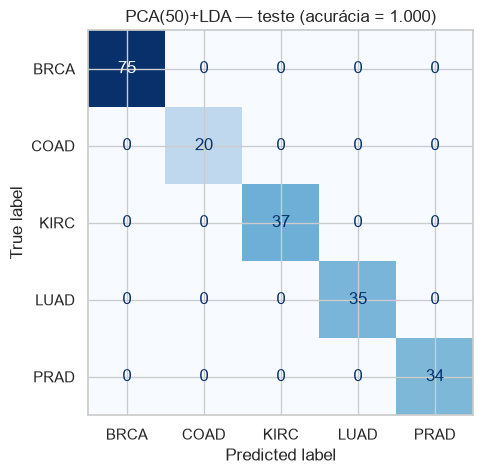

In [42]:
y_pred = pca_lda.predict(X_te)
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=classes), display_labels=classes).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"PCA(50)+LDA — teste (acurácia = {accuracy_score(y_te, y_pred):.3f})")
plt.show()

---
## Parte 6 — PCA × LDA lado a lado

Vamos reproduzir o slide *"Comparando LDA com PCA em 10000 genes"*, agora com os nossos dados. Para ser justo, os dois métodos são **ajustados no treino** e mostramos as amostras de **teste**.

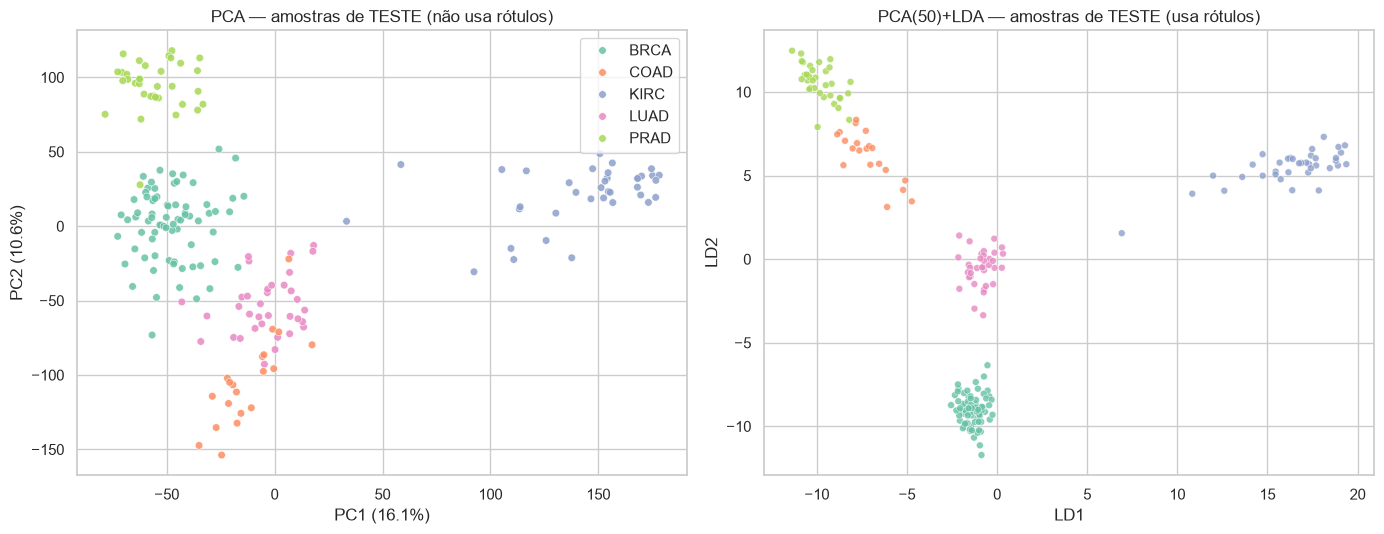

In [43]:
# PCA ajustado só no treino (para comparação justa com o LDA)
pca_tr = PCA(n_components=2, random_state=SEED).fit(X_tr)
Z_te_pca2 = pca_tr.transform(X_te)
ev_tr = 100 * pca_tr.explained_variance_ratio_

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=Z_te_pca2[:, 0], y=Z_te_pca2[:, 1], hue=y_te.values, hue_order=classes,
                palette=paleta, s=30, alpha=.85, ax=ax[0])
ax[0].set(title="PCA — amostras de TESTE (não usa rótulos)",
          xlabel=f"PC1 ({ev_tr[0]:.1f}%)", ylabel=f"PC2 ({ev_tr[1]:.1f}%)")
plot_ld(Z_te_pl, y_te, "PCA(50)+LDA — amostras de TESTE (usa rótulos)", ax[1], legenda=False)
plt.tight_layout(); plt.show()

### Comparação quantitativa

"Parecer separado" no gráfico é subjetivo. Vamos medir com duas métricas, **sempre em 2 dimensões** (PC1–PC2 × LD1–LD2):

1. **Silhueta** (de −1 a 1): quão perto cada amostra está do seu próprio grupo em comparação com o grupo vizinho. Maior = grupos mais compactos e separados.
2. **Acurácia de um k-NN** (k = 5 vizinhos) treinado no espaço 2D, com **validação cruzada de 5 partes**. Pergunta: *"se eu só tivesse esse gráfico 2D, conseguiria classificar amostras novas?"*

Na validação cruzada, cada etapa (PCA, LDA, k-NN) é **reajustada dentro de cada partição**, evitando vazamento de informação.

In [44]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

modelos = {
    "PCA (2 PCs)":        make_pipeline(PCA(n_components=2, random_state=SEED),
                                        KNeighborsClassifier(5)),
    "PCA(50)+LDA (2 LDs)": make_pipeline(PCA(n_components=50, random_state=SEED),
                                        LinearDiscriminantAnalysis(n_components=2),
                                        KNeighborsClassifier(5)),
}

resultados = []
for nome, modelo in modelos.items():
    t0 = time.time()
    acc = cross_val_score(modelo, X, y, cv=cv, scoring="accuracy")
    # Silhueta nas amostras de teste, com o embedding 2D ajustado no treino
    emb = modelo[:-1].fit(X_tr, y_tr).transform(X_te)
    sil = silhouette_score(emb, y_te)
    resultados.append({"método": nome, "acurácia k-NN (CV)": f"{acc.mean():.3f} ± {acc.std():.3f}",
                       "silhueta (teste)": round(sil, 3), "tempo (s)": round(time.time() - t0, 1)})

display(pd.DataFrame(resultados).set_index("método"))

,acurácia k-NN (CV),silhueta (teste),tempo (s)
método,,,
PCA (2 PCs),0.949 ± 0.009,0.523,9.1
PCA(50)+LDA (2 LDs),0.996 ± 0.005,0.763,11.3


### E se quisermos usar o mesmo número de dimensões do LDA?

O LDA com 5 classes tem no máximo 4 eixos. Quantas PCs seriam necessárias para atingir, sem rótulos, uma separação parecida? Vamos variar o número de componentes.

,PCA,PCA(50)+LDA
nº de dimensões,,
1,0.672,0.844
2,0.949,0.996
3,0.985,1.000
4,0.989,1.000


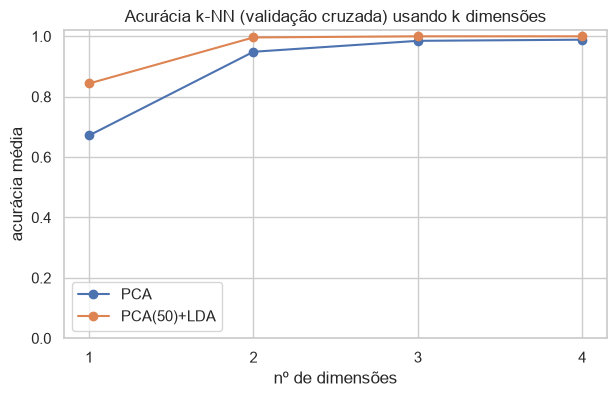

In [45]:
linhas = []
for k in [1, 2, 3, 4]:
    m_pca = make_pipeline(PCA(n_components=k, random_state=SEED), KNeighborsClassifier(5))
    m_lda = make_pipeline(PCA(n_components=50, random_state=SEED),
                          LinearDiscriminantAnalysis(n_components=k), KNeighborsClassifier(5))
    linhas.append({"nº de dimensões": k,
                   "PCA": cross_val_score(m_pca, X, y, cv=cv).mean(),
                   "PCA(50)+LDA": cross_val_score(m_lda, X, y, cv=cv).mean()})
tab = pd.DataFrame(linhas).set_index("nº de dimensões")
display(tab.round(3))

tab.plot(marker="o", figsize=(7, 4))
plt.title("Acurácia k-NN (validação cruzada) usando k dimensões")
plt.ylabel("acurácia média"); plt.xticks([1, 2, 3, 4]); plt.ylim(0, 1.02); plt.show()

**Para pensar:**

- Com **1 ou 2 dimensões**, qual método preserva melhor a informação sobre o tipo de câncer? Por quê?
- O PCA "gasta" as primeiras componentes com a direção de **maior variância**, que nem sempre é a que separa as classes (lembre-se do exemplo simulado da Parte 2). O LDA usa os rótulos e vai **direto** às direções que separam.
- Então o LDA é sempre melhor? **Não!** O LDA exige rótulos, tende ao sobreajuste quando há muitas variáveis para poucas amostras (Parte 5.2) e só enxerga diferenças que você já conhece. O PCA é ideal para **exploração**: controle de qualidade, detectar *outliers*, efeitos de lote (*batch effect*) e grupos inesperados.

---
## Parte 7 — Resumo

| | **PCA** | **LDA** |
|---|---|---|
| Tipo | **Não supervisionado** (não usa rótulos) | **Supervisionado** (precisa dos rótulos) |
| O que maximiza | Variância total dos dados projetados — SS(distâncias) | Razão de Fisher: distância entre médias / variância dentro das classes |
| Nº máximo de eixos | min(*n* − 1, *p*) | nº de classes − 1 |
| Eixos ordenados por | % da variação **total** explicada | % da variação **entre classes** explicada |
| *Loading scores* | Sim — quais genes conduzem cada PC | Sim — quais genes conduzem cada LD |
| Serve como classificador? | Não (apenas reduz dimensionalidade) | Sim |
| Risco quando p ≫ n | Baixo | **Alto** (sobreajuste) → usar PCA antes, regularização ou seleção de genes |
| Uso típico em bioinformática | Exploração, QC, efeito de lote, visualização | Separar/classificar grupos conhecidos (subtipos, resposta a droga) |

### Mensagens principais

1. **PCA = girar a reta** até maximizar a soma dos quadrados das projeções; o SVD faz isso para todas as PCs de uma vez.
2. **LDA = Fisher**: médias longe **e** classes compactas, ao mesmo tempo.
3. A direção de **maior variância nem sempre é a que separa as classes**.
4. Método supervisionado **sempre** deve ser avaliado em dados que ele não viu.

---
## Exercícios

Execute a célula seguinte com o **seu número USP**. Ela gera a **sua** versão dos exercícios: tabela, subamostra dos dados, parâmetros e cenário. Respostas obtidas com outro número USP serão consideradas incorretas.

Para que seus números batam com a correção, use sempre `random_state=0` no `PCA` e `StratifiedKFold(5, shuffle=True, random_state=0)` na validação cruzada.

1. **Sua tabela de ratos com 4 genes.** Use a tabela `P["tabela_ratos"]` (genes nas linhas, como no slide; lembre-se de transpor). Calcule as PCs, o *scree plot* e o gráfico PC1 × PC2. Informe: (a) a % de variação da PC1 e da PC2; (b) qual gene tem maior |loading| na PC1 e qual tem na PC2; (c) os ratos formam os mesmos dois grupos dos slides?

2. **Padronizar ou não?** Com `X_aluno`, calcule o PCA com 2 componentes **sem** e **com** `StandardScaler()` antes (`make_pipeline(StandardScaler(), PCA(...))`). Informe a % de variação da PC1 e da PC2 nos dois casos, compare os gráficos PC1 × PC2 e explique a diferença.

3. **Escolhendo o nº de PCs de forma honesta.** Divida `X_aluno`/`y_aluno` em treino e teste (`test_size=0.25`, `stratify`, `random_state=P["random_state_split"]`). Use `GridSearchCV` sobre o pipeline PCA+LDA (`pca__n_components` em [5, 10, 20, 50, 100, 200]) **apenas no treino**. Informe o *k* escolhido e a acurácia no teste.

4. **LDA com regularização.** Com a mesma divisão do Ex. 3, selecione os `P["n_genes_top"]` genes de maior variância **calculada só no treino** e treine `LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")`. Compare a acurácia de teste com a do PCA(50)+LDA. Por que a variância deve ser calculada só no treino? (Atenção: o solver `lsqr` classifica, mas não gera a projeção `transform`.)

5. **Seu par de cânceres.** Fique apenas com as amostras do par `P["par_cancer"]` em `X_aluno`. (a) Quantos eixos o LDA produz agora, e por quê? (b) Faça histogramas da projeção em PC1 e em LD1, coloridos pela classe, como na Parte 2. (c) Informe a silhueta da projeção em PC1. (d) Esse par é fácil ou difícil de separar? Que explicação biológica você daria?

6. **Seu cenário.** Leia `P["cenario"]`. Em até 5 linhas: você usaria PCA, LDA ou os dois? Em que ordem e com que cuidados?

In [46]:
# ===============================================================
# EXERCÍCIOS PERSONALIZADOS — digite o SEU número USP abaixo
# ===============================================================
NUSP = 15638792          # <<< troque pelo seu número USP (somente dígitos)

from itertools import combinations
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

def parametros(nusp):
    # Gera, a partir do número USP, todos os parâmetros dos exercícios.
    # O mesmo número USP gera SEMPRE os mesmos parâmetros (o professor consegue conferir).
    nusp = int(nusp)
    assert nusp > 0, "Digite o seu número USP na variável NUSP!"
    rng = np.random.default_rng(nusp)
    p = {"seed": nusp % (2**31 - 1)}

    # --- Ex. 1: tabela própria de 6 ratos × 4 genes ---
    # Ratos 1–3 formam um grupo e ratos 4–6 outro; cada gene tem um efeito diferente.
    base   = rng.uniform(2, 8, size=4)                       # nível basal de cada gene
    efeito = rng.uniform(0.5, 3.0, size=4) * rng.choice([-1, 1], size=4)
    forte  = rng.integers(4)                                  # um gene com efeito grande
    efeito[forte] = rng.uniform(6, 9) * rng.choice([-1, 1])
    grupo  = np.array([1, 1, 1, 0, 0, 0])
    tab = base[:, None] + efeito[:, None] * grupo[None, :] + rng.normal(0, 0.8, size=(4, 6))
    p["tabela_ratos"] = pd.DataFrame(np.clip(tab, 0.1, None).round(1),
                                     index=[f"Gene {i+1}" for i in range(4)],
                                     columns=[f"Mouse {j+1}" for j in range(6)])

    # --- Ex. 2 a 5: cada aluno trabalha com uma subamostra própria ---
    p["frac_amostras"] = 0.85      # 85% dos tumores, sorteados
    p["n_genes_sub"]   = 2000      # 2.000 genes sorteados entre os ~20 mil

    # --- Ex. 3: divisão treino/teste própria ---
    p["random_state_split"] = int(rng.integers(1, 10_000))

    # --- Ex. 4: nº de genes mais variáveis para o LDA com shrinkage ---
    p["n_genes_top"] = int(rng.choice([200, 400, 600, 800, 1000]))

    # --- Ex. 5: um par de tipos de câncer ---
    pares = list(combinations(["BRCA", "COAD", "KIRC", "LUAD", "PRAD"], 2))   # 10 pares
    p["par_cancer"] = pares[int(rng.integers(len(pares)))]

    # --- Ex. 6: um cenário de projeto ---
    cenarios = [
        "Você recebeu 300 amostras de RNA-Seq de tumores de pulmão sequenciadas em 3 hospitais diferentes "
        "e suspeita de efeito de lote (batch effect).",
        "Um laboratório quer saber se 5 subtipos moleculares de câncer de mama, já anotados por especialistas, "
        "podem ser distinguidos pela expressão gênica.",
        "Você tem 40 pacientes (20 responderam a uma droga, 20 não) e 18 mil genes medidos.",
        "Você quer verificar se há amostras mal rotuladas ou contaminadas antes de uma análise de expressão diferencial.",
        "Um grupo descobriu 3 grupos de pacientes por agrupamento (clustering) e quer um classificador para novos pacientes.",
        "Você precisa resumir 20 mil genes em poucas variáveis para alimentar um modelo de sobrevivência.",
    ]
    p["cenario"] = cenarios[int(rng.integers(len(cenarios)))]
    return p

def subamostra(X, y, p):
    # Sorteia os genes e os tumores (estratificado por tipo de câncer) do aluno
    genes = np.random.default_rng(p["seed"]).choice(X.columns, size=min(p["n_genes_sub"], X.shape[1]), replace=False)
    Xs, _, ys, _ = train_test_split(X[sorted(genes)], y, train_size=p["frac_amostras"],
                                    stratify=y, random_state=p["seed"])
    return Xs, ys

P = parametros(NUSP)
print(f"Número USP: {NUSP}\n")
print("Ex. 1 — sua tabela de expressão (genes nas linhas, como no slide):")
display(P["tabela_ratos"])
print(f"Ex. 2–5 — você usará {int(100*P['frac_amostras'])}% dos tumores e {P['n_genes_sub']} genes, sorteados para você")
print(f"Ex. 3   — random_state da divisão treino/teste: {P['random_state_split']}")
print(f"Ex. 4   — nº de genes mais variáveis: {P['n_genes_top']}")
print(f"Ex. 5   — par de tipos de câncer: {P['par_cancer'][0]} × {P['par_cancer'][1]}")
print(f"Ex. 6   — cenário: {P['cenario']}")

X_aluno, y_aluno = subamostra(X, y, P)
print(f"\nSua subamostra: {X_aluno.shape[0]} tumores × {X_aluno.shape[1]} genes  ->  use X_aluno e y_aluno")

Número USP: 15638792

Ex. 1 — sua tabela de expressão (genes nas linhas, como no slide):


,Mouse 1,Mouse 2,Mouse 3,Mouse 4,Mouse 5,Mouse 6
Gene 1,11.3,11.3,9.6,1.6,2.1,1.9
Gene 2,8.6,9.7,8.1,6.1,7.7,5.1
Gene 3,6.1,5.3,5.7,6.1,7.0,7.2
Gene 4,0.2,0.1,1.2,4.6,3.5,2.8


Ex. 2–5 — você usará 85% dos tumores e 2000 genes, sorteados para você
Ex. 3   — random_state da divisão treino/teste: 7039
Ex. 4   — nº de genes mais variáveis: 1000
Ex. 5   — par de tipos de câncer: BRCA × COAD
Ex. 6   — cenário: Você precisa resumir 20 mil genes em poucas variáveis para alimentar um modelo de sobrevivência.

Sua subamostra: 680 tumores × 2000 genes  ->  use X_aluno e y_aluno


---
## Resolução dos Exercícios (NUSP 15638792)

### Exercício 1 — Sua tabela de ratos com 4 genes

(a) Variação explicada -> PC1: 95.83% | PC2: 2.75% (soma: 98.57%)


,PC1,PC2
Gene 1,0.9008,-0.1545
Gene 2,0.2675,0.8869
Gene 3,-0.1041,-0.2248
Gene 4,-0.3259,0.3728


(b) Maior |loading| na PC1: Gene 1 | na PC2: Gene 2


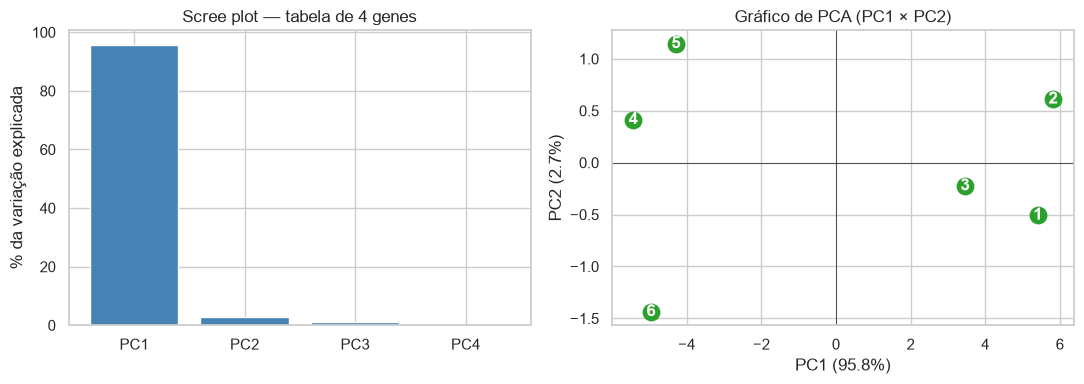

In [47]:
# ---------------------------------------------------------------
# Exercício 1 — PCA na sua tabela de 6 ratos × 4 genes
# ---------------------------------------------------------------
# Transpomos para o formato do scikit-learn: linhas = amostras (ratos), colunas = variáveis (genes)
X_ratos_ex1 = P["tabela_ratos"].T

# Ajustamos o PCA com random_state=0 (regra da correção) mantendo todas as 4 PCs
pca_ex1 = PCA(random_state=0).fit(X_ratos_ex1)
Z_ratos_ex1 = pca_ex1.transform(X_ratos_ex1)
ev_ex1 = 100 * pca_ex1.explained_variance_ratio_

print(f"(a) Variação explicada -> PC1: {ev_ex1[0]:.2f}% | PC2: {ev_ex1[1]:.2f}% (soma: {ev_ex1[:2].sum():.2f}%)")

# Loading scores: peso de cada gene em PC1 e PC2 (maior |loading| = maior influência)
loadings_ex1 = pd.DataFrame(pca_ex1.components_[:2].T, index=X_ratos_ex1.columns, columns=["PC1", "PC2"])
display(loadings_ex1.round(4))
print(f"(b) Maior |loading| na PC1: {loadings_ex1['PC1'].abs().idxmax()} | na PC2: {loadings_ex1['PC2'].abs().idxmax()}")

# Visualização: scree plot + projeção PC1 × PC2
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar([f"PC{i+1}" for i in range(len(ev_ex1))], ev_ex1, color="steelblue")
ax[0].set(title="Scree plot — tabela de 4 genes", ylabel="% da variação explicada")

ax[1].scatter(Z_ratos_ex1[:, 0], Z_ratos_ex1[:, 1], s=140, c="tab:green")
for i, nome in enumerate(X_ratos_ex1.index):
    ax[1].annotate(nome.split()[-1], (Z_ratos_ex1[i, 0], Z_ratos_ex1[i, 1]),
                   ha="center", va="center", color="white", fontweight="bold")
ax[1].axhline(0, c="k", lw=0.5); ax[1].axvline(0, c="k", lw=0.5)
ax[1].set(title="Gráfico de PCA (PC1 × PC2)",
          xlabel=f"PC1 ({ev_ex1[0]:.1f}%)", ylabel=f"PC2 ({ev_ex1[1]:.1f}%)")
plt.tight_layout(); plt.show()

Respostas do Exercício 1:

(a) A PC1 explica 95,83% da variação e a PC2 explica 2,75%, somando 98,58% de toda a variação dos 4 genes.

(b) O gene com maior loading em módulo na PC1 é o Gene 1 (0,9008), e na PC2 é o Gene 2 (0,8869).

(c) Sim. Mesmo sem receber rótulos, a PC1 separa bem os Ratos 1, 2 e 3 (com valores positivos, à direita) dos Ratos 4, 5 e 6 (com valores negativos, à esquerda), formando os mesmos dois grupos dos slides.

### Exercício 2 — Padronizar ou não?

SEM StandardScaler -> PC1: 15.24% | PC2: 11.27% (soma: 26.51%) | silhueta: 0.533
COM StandardScaler -> PC1: 10.98% | PC2: 8.97% (soma: 19.95%) | silhueta: 0.131


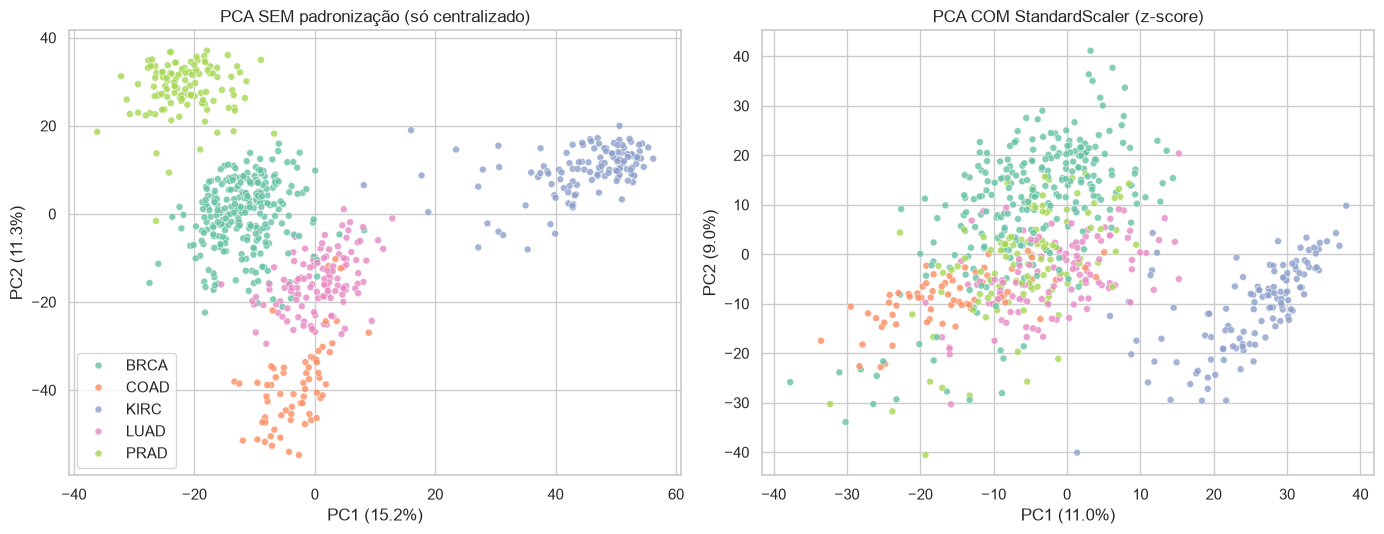

In [48]:
# ---------------------------------------------------------------
# Exercício 2 — PCA com 2 componentes SEM e COM StandardScaler
# ---------------------------------------------------------------
# 1) Sem padronização: apenas centralização (feita internamente pelo PCA)
pca_sem = PCA(n_components=2, random_state=0)
Z_sem = pca_sem.fit_transform(X_aluno)
ev_sem = 100 * pca_sem.explained_variance_ratio_

# 2) Com padronização (z-score): todos os genes passam a ter média 0 e variância 1
pipe_com = make_pipeline(StandardScaler(), PCA(n_components=2, random_state=0))
Z_com = pipe_com.fit_transform(X_aluno)
ev_com = 100 * pipe_com.named_steps["pca"].explained_variance_ratio_

print(f"SEM StandardScaler -> PC1: {ev_sem[0]:.2f}% | PC2: {ev_sem[1]:.2f}% (soma: {ev_sem.sum():.2f}%) | silhueta: {silhouette_score(Z_sem, y_aluno):.3f}")
print(f"COM StandardScaler -> PC1: {ev_com[0]:.2f}% | PC2: {ev_com[1]:.2f}% (soma: {ev_com.sum():.2f}%) | silhueta: {silhouette_score(Z_com, y_aluno):.3f}")

# Comparação visual dos dois espaços PC1 × PC2
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=Z_sem[:, 0], y=Z_sem[:, 1], hue=y_aluno.values, hue_order=classes,
                palette=paleta, s=25, alpha=0.8, ax=ax[0])
ax[0].set(title="PCA SEM padronização (só centralizado)",
          xlabel=f"PC1 ({ev_sem[0]:.1f}%)", ylabel=f"PC2 ({ev_sem[1]:.1f}%)")

sns.scatterplot(x=Z_com[:, 0], y=Z_com[:, 1], hue=y_aluno.values, hue_order=classes,
                palette=paleta, s=25, alpha=0.8, ax=ax[1], legend=False)
ax[1].set(title="PCA COM StandardScaler (z-score)",
          xlabel=f"PC1 ({ev_com[0]:.1f}%)", ylabel=f"PC2 ({ev_com[1]:.1f}%)")
plt.tight_layout(); plt.show()

Respostas do Exercício 2:

Sem o StandardScaler, a PC1 explica 15,24% da variação e a PC2 explica 11,27%, totalizando 26,51% (com silhueta de 0,533). Com o StandardScaler, a PC1 cai para 10,98% e a PC2 para 8,97%, somando 19,95% (com silhueta de 0,131).

Sem padronizar, os genes em escala log que realmente variam muito entre os tipos de tumor acabam pesando mais nas primeiras componentes, o que concentra melhor a variância e ajuda a separar os cinco tipos de câncer. Quando aplicamos o StandardScaler, todos os 2.000 genes passam a ter variância igual a 1, incluindo genes pouco variáveis ou dominados por ruído. Isso amplifica o ruído, espalha a variância por mais dimensões e deixa os grupos bem mais misturados no gráfico PC1 x PC2.

### Exercício 3 — Escolhendo o nº de PCs de forma honesta

In [49]:
# ---------------------------------------------------------------
# Exercício 3 — Seleção honesta do nº de PCs com GridSearchCV
# ---------------------------------------------------------------
# Divisão estratificada em 75% treino e 25% teste usando o random_state sorteado
X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(
    X_aluno, y_aluno, test_size=0.25, stratify=y_aluno,
    random_state=P["random_state_split"]
)

# Validação cruzada estratificada de 5 folds com random_state=0 (regra da correção)
cv_ex3 = StratifiedKFold(5, shuffle=True, random_state=0)

# Pipeline garante que o PCA seja ajustado dentro de cada fold, sem vazamento de dados
pipe_ex3 = make_pipeline(PCA(random_state=0), LinearDiscriminantAnalysis())

# Busca do melhor número de PCs exclusivamente no conjunto de treino
grid_ex3 = GridSearchCV(
    pipe_ex3,
    param_grid={"pca__n_components": [5, 10, 20, 50, 100, 200]},
    cv=cv_ex3,
    scoring="accuracy"
)
grid_ex3.fit(X_tr_a, y_tr_a)

# Tabela resumo dos resultados na validação cruzada
res_cv = pd.DataFrame({
    "k (n_components)": grid_ex3.cv_results_["param_pca__n_components"],
    "acurácia média (CV)": grid_ex3.cv_results_["mean_test_score"],
    "desvio padrão (CV)": grid_ex3.cv_results_["std_test_score"],
})
display(res_cv.round(4))

print(f"Melhor k escolhido pelo GridSearchCV: {grid_ex3.best_params_['pca__n_components']}")
print(f"Acurácia no conjunto de TESTE:        {grid_ex3.score(X_te_a, y_te_a):.4f}")

,k (n_components),acurácia média (CV),desvio padrão (CV)
0,5,0.9882,0.0073
1,10,0.9961,0.0048
2,20,0.9961,0.0048
3,50,0.9961,0.0048
4,100,0.9961,0.0048
5,200,0.9961,0.0048


Melhor k escolhido pelo GridSearchCV: 10
Acurácia no conjunto de TESTE:        1.0000


Respostas do Exercício 3:

O melhor valor de k escolhido pelo GridSearchCV no conjunto de treino foi k = 10, alcançando acurácia média de 0,9961 (com desvio padrão de 0,0048) na validação cruzada. Embora k = 20, 50, 100 e 200 tenham empatado com a mesma média, o GridSearchCV seleciona o primeiro valor que atinge o máximo, que também é o modelo mais simples. Avaliado no conjunto de teste, esse modelo obteve acurácia de 1,0000 (100%).

### Exercício 4 — LDA com regularização

In [50]:
# ---------------------------------------------------------------
# Exercício 4 — LDA com regularização (shrinkage) nos top genes
# ---------------------------------------------------------------
# Reutilizamos exatamente o mesmo split (X_tr_a, X_te_a, y_tr_a, y_te_a) do Ex. 3.
# Calculamos a variância APENAS no treino para evitar vazamento de informação do teste.
top_genes = X_tr_a.var(axis=0).nlargest(P["n_genes_top"]).index

# LDA regularizado: solver="lsqr" + shrinkage="auto" estabiliza a covariância com p > n
lda_shr = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
lda_shr.fit(X_tr_a[top_genes], y_tr_a)
acc_shr = lda_shr.score(X_te_a[top_genes], y_te_a)

# Comparação com PCA(50) + LDA no mesmo split treino/teste
pca50_lda = make_pipeline(PCA(n_components=50, random_state=0), LinearDiscriminantAnalysis())
pca50_lda.fit(X_tr_a, y_tr_a)
acc_pca50 = pca50_lda.score(X_te_a, y_te_a)

print(f"LDA com shrinkage (top {P['n_genes_top']} genes) — acurácia no TESTE: {acc_shr:.4f}")
print(f"PCA(50) + LDA                            — acurácia no TESTE: {acc_pca50:.4f}")

LDA com shrinkage (top 1000 genes) — acurácia no TESTE: 1.0000
PCA(50) + LDA                            — acurácia no TESTE: 1.0000


Respostas do Exercício 4:

No conjunto de teste, tanto o LDA com shrinkage treinado nos 1.000 genes mais variáveis quanto o pipeline PCA(50) + LDA atingiram acurácia de 1,0000 (100%). Isso mostra que regularizar a matriz de covariância é uma alternativa eficaz ao uso prévio de PCA quando há mais genes do que amostras.

A variância precisa ser calculada somente no conjunto de treino para evitar vazamento de dados (data leakage). Se incluíssemos as amostras de teste nessa escolha, estaríamos usando informação do teste durante a preparação do modelo, o que tornaria a avaliação final otimista e não representativa de dados novos.

### Exercício 5 — Seu par de cânceres (BRCA × COAD)

Amostras do par BRCA × COAD: 321 tumores ({'BRCA': np.int64(255), 'COAD': np.int64(66)})
(a) Número de eixos produzidos pelo LDA: 1 (= nº de classes - 1 = 2 - 1)
(c) Silhueta da projeção em PC1:         0.8405


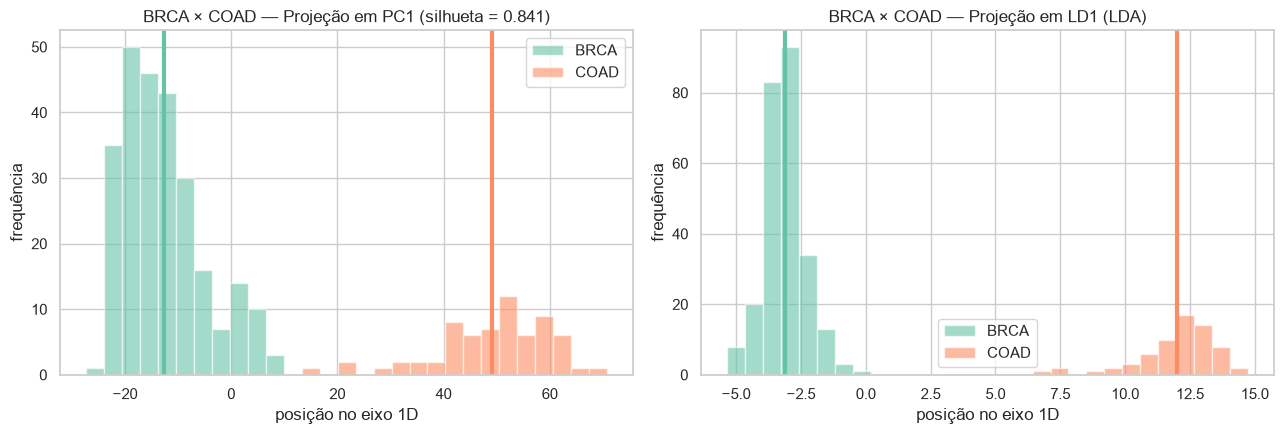

In [51]:
# ---------------------------------------------------------------
# Exercício 5 — Separação do par de cânceres sorteado (BRCA × COAD)
# ---------------------------------------------------------------
c1, c2 = P["par_cancer"]
mask_par = y_aluno.isin([c1, c2])
X_par, y_par = X_aluno[mask_par], y_aluno[mask_par]
print(f"Amostras do par {c1} × {c2}: {X_par.shape[0]} tumores ({dict(y_par.value_counts())})")

# Projeção 1D com PCA (não supervisionado)
Z_pc1 = PCA(n_components=1, random_state=0).fit_transform(X_par)
sil_pc1 = silhouette_score(Z_pc1, y_par)

# Projeção 1D com LDA (supervisionado): com 2 classes, o máximo é 2 - 1 = 1 eixo
lda_par = LinearDiscriminantAnalysis(n_components=1).fit(X_par, y_par)
Z_ld1 = lda_par.transform(X_par)

print(f"(a) Número de eixos produzidos pelo LDA: {Z_ld1.shape[1]} (= nº de classes - 1 = 2 - 1)")
print(f"(c) Silhueta da projeção em PC1:         {sil_pc1:.4f}")

# (b) Histogramas de PC1 e LD1 coloridos pela classe, com médias marcadas (como na Parte 2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for eixo, Z, titulo in [
    (ax[0], Z_pc1[:, 0], f"Projeção em PC1 (silhueta = {sil_pc1:.3f})"),
    (ax[1], Z_ld1[:, 0], "Projeção em LD1 (LDA)"),
]:
    bins = np.linspace(Z.min(), Z.max(), 30)
    for cl in [c1, c2]:
        vals = Z[y_par == cl]
        eixo.hist(vals, bins=bins, alpha=0.6, color=paleta[cl], label=cl)
        eixo.axvline(vals.mean(), color=paleta[cl], lw=3)
    eixo.set(title=f"{c1} × {c2} — {titulo}", xlabel="posição no eixo 1D", ylabel="frequência")
    eixo.legend()
plt.tight_layout(); plt.show()

Respostas do Exercício 5:

(a) O LDA produz apenas 1 eixo (LD1), porque o número máximo de eixos discriminantes é igual ao número de classes menos 1 (neste caso, 2 - 1 = 1).

(b) Os histogramas das projeções em PC1 e LD1, coloridos por BRCA e COAD e com as médias destacadas, estão exibidos na figura acima.

(c) A silhueta da projeção em PC1 é de 0,8405.

(d) Esse par é muito fácil de separar. Mesmo na projeção não supervisionada em PC1, BRCA e COAD não apresentam sobreposição e já atingem uma silhueta alta (0,8405). Biologicamente, isso faz sentido porque o carcinoma invasivo de mama (BRCA) e o adenocarcinoma de cólon (COAD) vêm de órgãos e tecidos muito diferentes, mantendo padrões de expressão gênica tecido-específicos bem distintos.

### Exercício 6 — Seu cenário

Cenário sorteado: Você precisa resumir 20 mil genes em poucas variáveis para alimentar um modelo de sobrevivência.

Resposta: Eu usaria apenas PCA, e não LDA, porque o objetivo é resumir 20 mil genes em poucas variáveis numéricas sem separar classes discretas fixas (modelos de sobrevivência lidam com tempo até evento e censura). Primeiro faria o pré-processamento removendo genes constantes e mantendo os dados em escala log; depois ajustaria o PCA exclusivamente no conjunto de treino, dentro de um pipeline ou validação cruzada, para evitar vazamento de dados. A escolha do número de componentes deve considerar a variância acumulada e o desempenho do próprio modelo de sobrevivência, lembrando que as direções de maior variância nem sempre são as mais relacionadas à sobrevida.